# Курсовая работа по дисциплине “Машинное обучение”
## Выполнена Благовестным Д.И. ПМ23-5
## Тема: "Оптимизация методов борьбы с перекосом классов в машинном обучении"


## Введение:
В задачах машинного обучения широко распространена проблема дисбаланса классов, при которой одни классы (обычно так называемый мажоритарный класс) представлены в выборке значительно чаще, чем другие (миноритарные). Модели, обученные на таких несбалансированных данных, склонны игнорировать редкие случаи, фокусируясь на наиболее часто встречающихся примерах. Это приводит к тому, что, несмотря на высокие показатели общей точности, модель фактически не справляется с задачей классификации объектов редкого класса.

Классический пример — задачи обнаружения мошенничества или диагностики заболеваний. В обоих случаях «нормальные» события (законные транзакции, здоровые пациенты) составляют подавляющее большинство, в то время как аномалии (мошенничество, заболевание) встречаются редко, но имеют высокую значимость. Без применения специализированных методов модель может достигать, например, точности выше 90 %, просто предсказывая мажоритарный класс для всех наблюдений, при этом практически полностью игнорируя целевой (миноритарный) класс.

Таким образом, разработка и внедрение методов, способных эффективно справляться с дисбалансом классов, является важнейшей задачей при построении надёжных и точных моделей классификации.

Существующие подходы к решению этой проблемы можно условно разделить на три уровня:

Уровень данных (data-level) — включает методы изменения обучающей выборки, такие как oversampling (увеличение числа объектов миноритарного класса) и undersampling (уменьшение числа объектов мажоритарного класса);

Уровень алгоритма (algorithm-level) — предполагает модификацию самого процесса обучения модели без изменения данных, например, через взвешивание классов в функции потерь или смещение порога классификации;

Ансамблевый и гибридный уровень (ensemble/hybrid-level) — объединяет идеи первых двух подходов с ансамблированием моделей, включая адаптированные методы Bagging и Boosting.

В данной работе проводится комплексное исследование методов борьбы с дисбалансом классов с акцентом на их практическую эффективность применительно к задаче выявления мошеннических транзакций. Рассматриваются современные подходы на всех трёх уровнях обработки: методы балансировки данных (включая oversampling и undersampling), алгоритмические модификации базовых моделей, а также специализированные ансамбли. Для реализации используются инструменты языка Python, включая библиотеки scikit-learn, imbalanced-learn, XGBoost, а также пользовательские реализации. Основная цель — оптимизация качества классификации в условиях выраженного дисбаланса классов. Для оценки эффективности применяемых подходов используется набор метрик, чувствительных к несбалансированности, что позволяет выявить наиболее продуктивные стратегии для решения задач данного типа.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

random_state = 25

## 1. Выбор данных

Для демонстрации проблемы дисбаланса классов и последующего анализа эффективности методов борьбы с ним необходимо использовать набор данных, в котором перекос между классами выражен особенно явно. Одним из широко известных и подходящих для этой цели является датасет Credit Card Fraud Detection, доступный на платформе Kaggle (https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).

Данный набор содержит данные по кредитным транзакциям, совершённым европейскими держателями карт в сентябре 2013 года. В выборке представлены транзакции, зафиксированные в течение двух дней. Всего в датасете содержится 284 807 записей, из которых лишь 492 являются мошенническими, что составляет около 0.172 % — ярко выраженный дисбаланс между классами.

Целью является построение классификатора, способного выявлять мошеннические транзакции, несмотря на их крайне малую долю в выборке. Этот набор данных представляет собой типичный пример прикладной задачи с сильным дисбалансом классов, характерной для сферы финансов, где пропущенные случаи мошенничества могут привести к серьёзным убыткам.

## 2. Предварительный анализ и очистка данных

### Иллюстрация структуры данных

In [ ]:
df = pd.read_csv('creditcard.csv')
display(df.head())
print("Размер датасета:", df.shape)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Размер датасета: (284807, 31)


Датасет содержит 284 807 записей и 31 столбец, включая 30 признаков и одну целевую переменную Class.

### Описание атрибутов

Данный набор данных включает только числовые признаки, большая часть которых получена в результате преобразования методом главных компонент (PCA). Это было сделано разработчиками датасета из соображений конфиденциальности, в связи с чем исходные имена и значения признаков не разглашаются.

Всего в наборе содержатся следующие переменные:

- V1–V28 — анонимизированные признаки, представляющие собой главные компоненты, полученные в результате применения PCA. Они сохраняют основную информацию из исходных данных и используются для построения модели, однако их семантика неизвестна;

- Time — количество секунд, прошедших с момента первой транзакции в наборе. Этот признак представляет собой временную метку, измеренную относительно начала сбора данных;

- Amount — сумма, потраченная в данной транзакции. В отличие от других признаков, не подвергалась PCA-преобразованию;

- Class — целевой признак, принимающий значение 1 для мошеннических транзакций и 0 для обычных.

### Проверка на пропущенные значения

In [ ]:
print("Пропущенные значения по столбцам:")
print(df.isnull().sum())

Пропущенные значения по столбцам:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


В датасете отсутствуют пропущенные значения — все строки и признаки заполнены полностью

### Распределение классов

In [ ]:
df['Class'].value_counts(normalize=True)  # в долях

,proportion
Class,
0,0.998273
1,0.001727


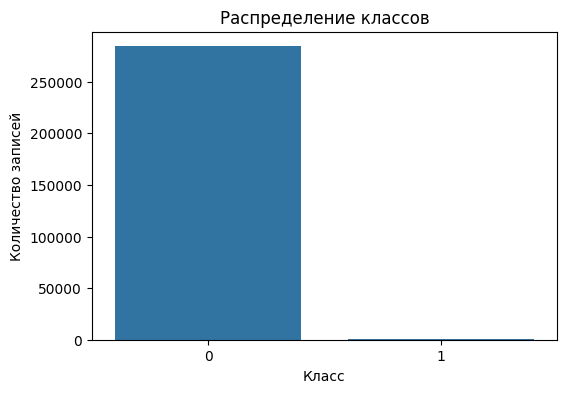

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество записей")
plt.show()

Датасет демонстрирует сильный дисбаланс классов: положительный класс (Class = 1), соответствующий мошенническим транзакциям, составляет всего 0.173 % от общего числа наблюдений.

Такой выраженный перекос подтверждает применимость данного набора данных для анализа и сравнения различных стратегий борьбы с дисбалансом классов.

### Статистическая информация по количественным признакам

In [ ]:
display(df.describe())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Большинство признаков имеют среднее значение, близкое к нулю, и примерно одинаковый разброс значений (стандартное отклонение около единицы). Это связано с тем, что к данным был применён метод главных компонент (PCA), который автоматически центрирует и масштабирует признаки. Такое преобразование делает данные более удобными для обучения моделей, особенно чувствительных к масштабу признаков.

Поля Time и Amount, не подвергавшиеся PCA, демонстрируют большой разброс значений, особенно Amount, где максимальная сумма транзакции достигает 25 691.16, при медиане в 22.0. Это может указывать на наличие выбросов, что следует учесть при построении моделей или при масштабировании признаков.

## 3. Описательный анализ данных

### Шкалы измерения

Для переменных V1–V28, полученных с помощью метода главных компонент (PCA), информация о шкалах измерения отсутствует. В то же время признаки Time и Amount представлены в секундах (время, прошедшее с начала сбора данных) и евро (сумма транзакции) соответственно. В рамках рассматриваемой задачи шкалы измерения не имеют первостепенного значения.

### Распределение признаков

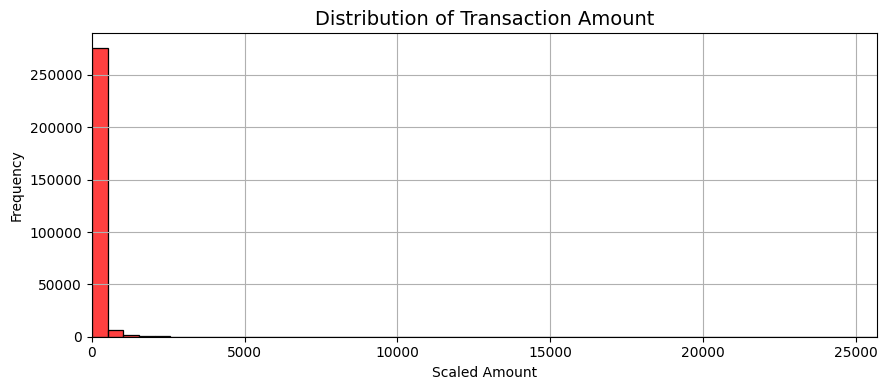

In [ ]:
amount_val = df['Amount'].values
plt.figure(figsize=(9, 4))
sns.histplot(amount_val, color='r', bins=50)
plt.title('Distribution of Transaction Amount', fontsize=14)
plt.xlabel('Scaled Amount')
plt.ylabel('Frequency')
plt.xlim([min(amount_val), max(amount_val)])
plt.grid(True)
plt.tight_layout()
plt.show()

Распределение суммы транзакций демонстрирует сильную положительную асимметрию: подавляющее большинство операций связано с малыми суммами, тогда как крупные транзакции встречаются значительно реже. Это соответствует типичной структуре потребительских расходов — регулярные небольшие покупки и редкие крупные переводы.

Распределение имеет выраженный тяжёлый правый хвост, что свидетельствует о наличии выбросов. Такие значения могут существенно влиять на обучение моделей, особенно без предварительного масштабирования.

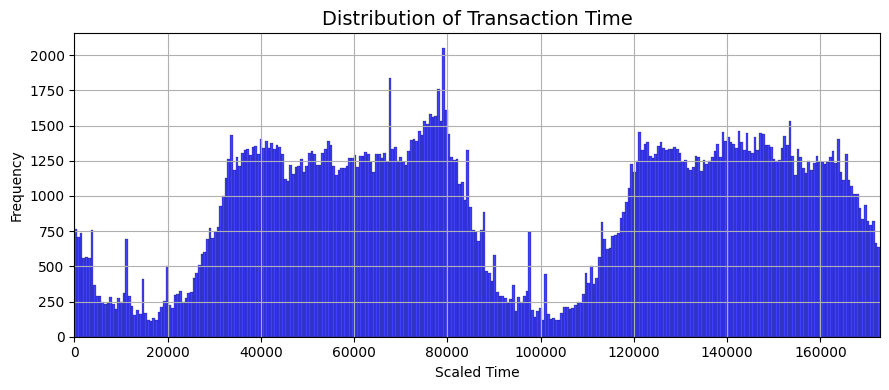

In [ ]:
time_val = df['Time'].values
plt.figure(figsize=(9, 4))
sns.histplot(time_val, color='b', bins=300)
plt.title('Distribution of Transaction Time', fontsize=14)
plt.xlabel('Scaled Time')
plt.ylabel('Frequency')
plt.xlim([min(time_val), max(time_val)])
plt.grid(True)
plt.tight_layout()
plt.show()

Признак Time, отражающий количество секунд с момента первой транзакции в выборке, демонстрирует неравномерное распределение. Можно заметить отдельные пики активности и периоды с пониженной частотой транзакций.
Такие колебания могут быть связаны с суточным ритмом пользовательской активности (например, меньшим количеством транзакций ночью) или указывать на всплески, потенциально связанные с аномальными или мошенническими действиями.

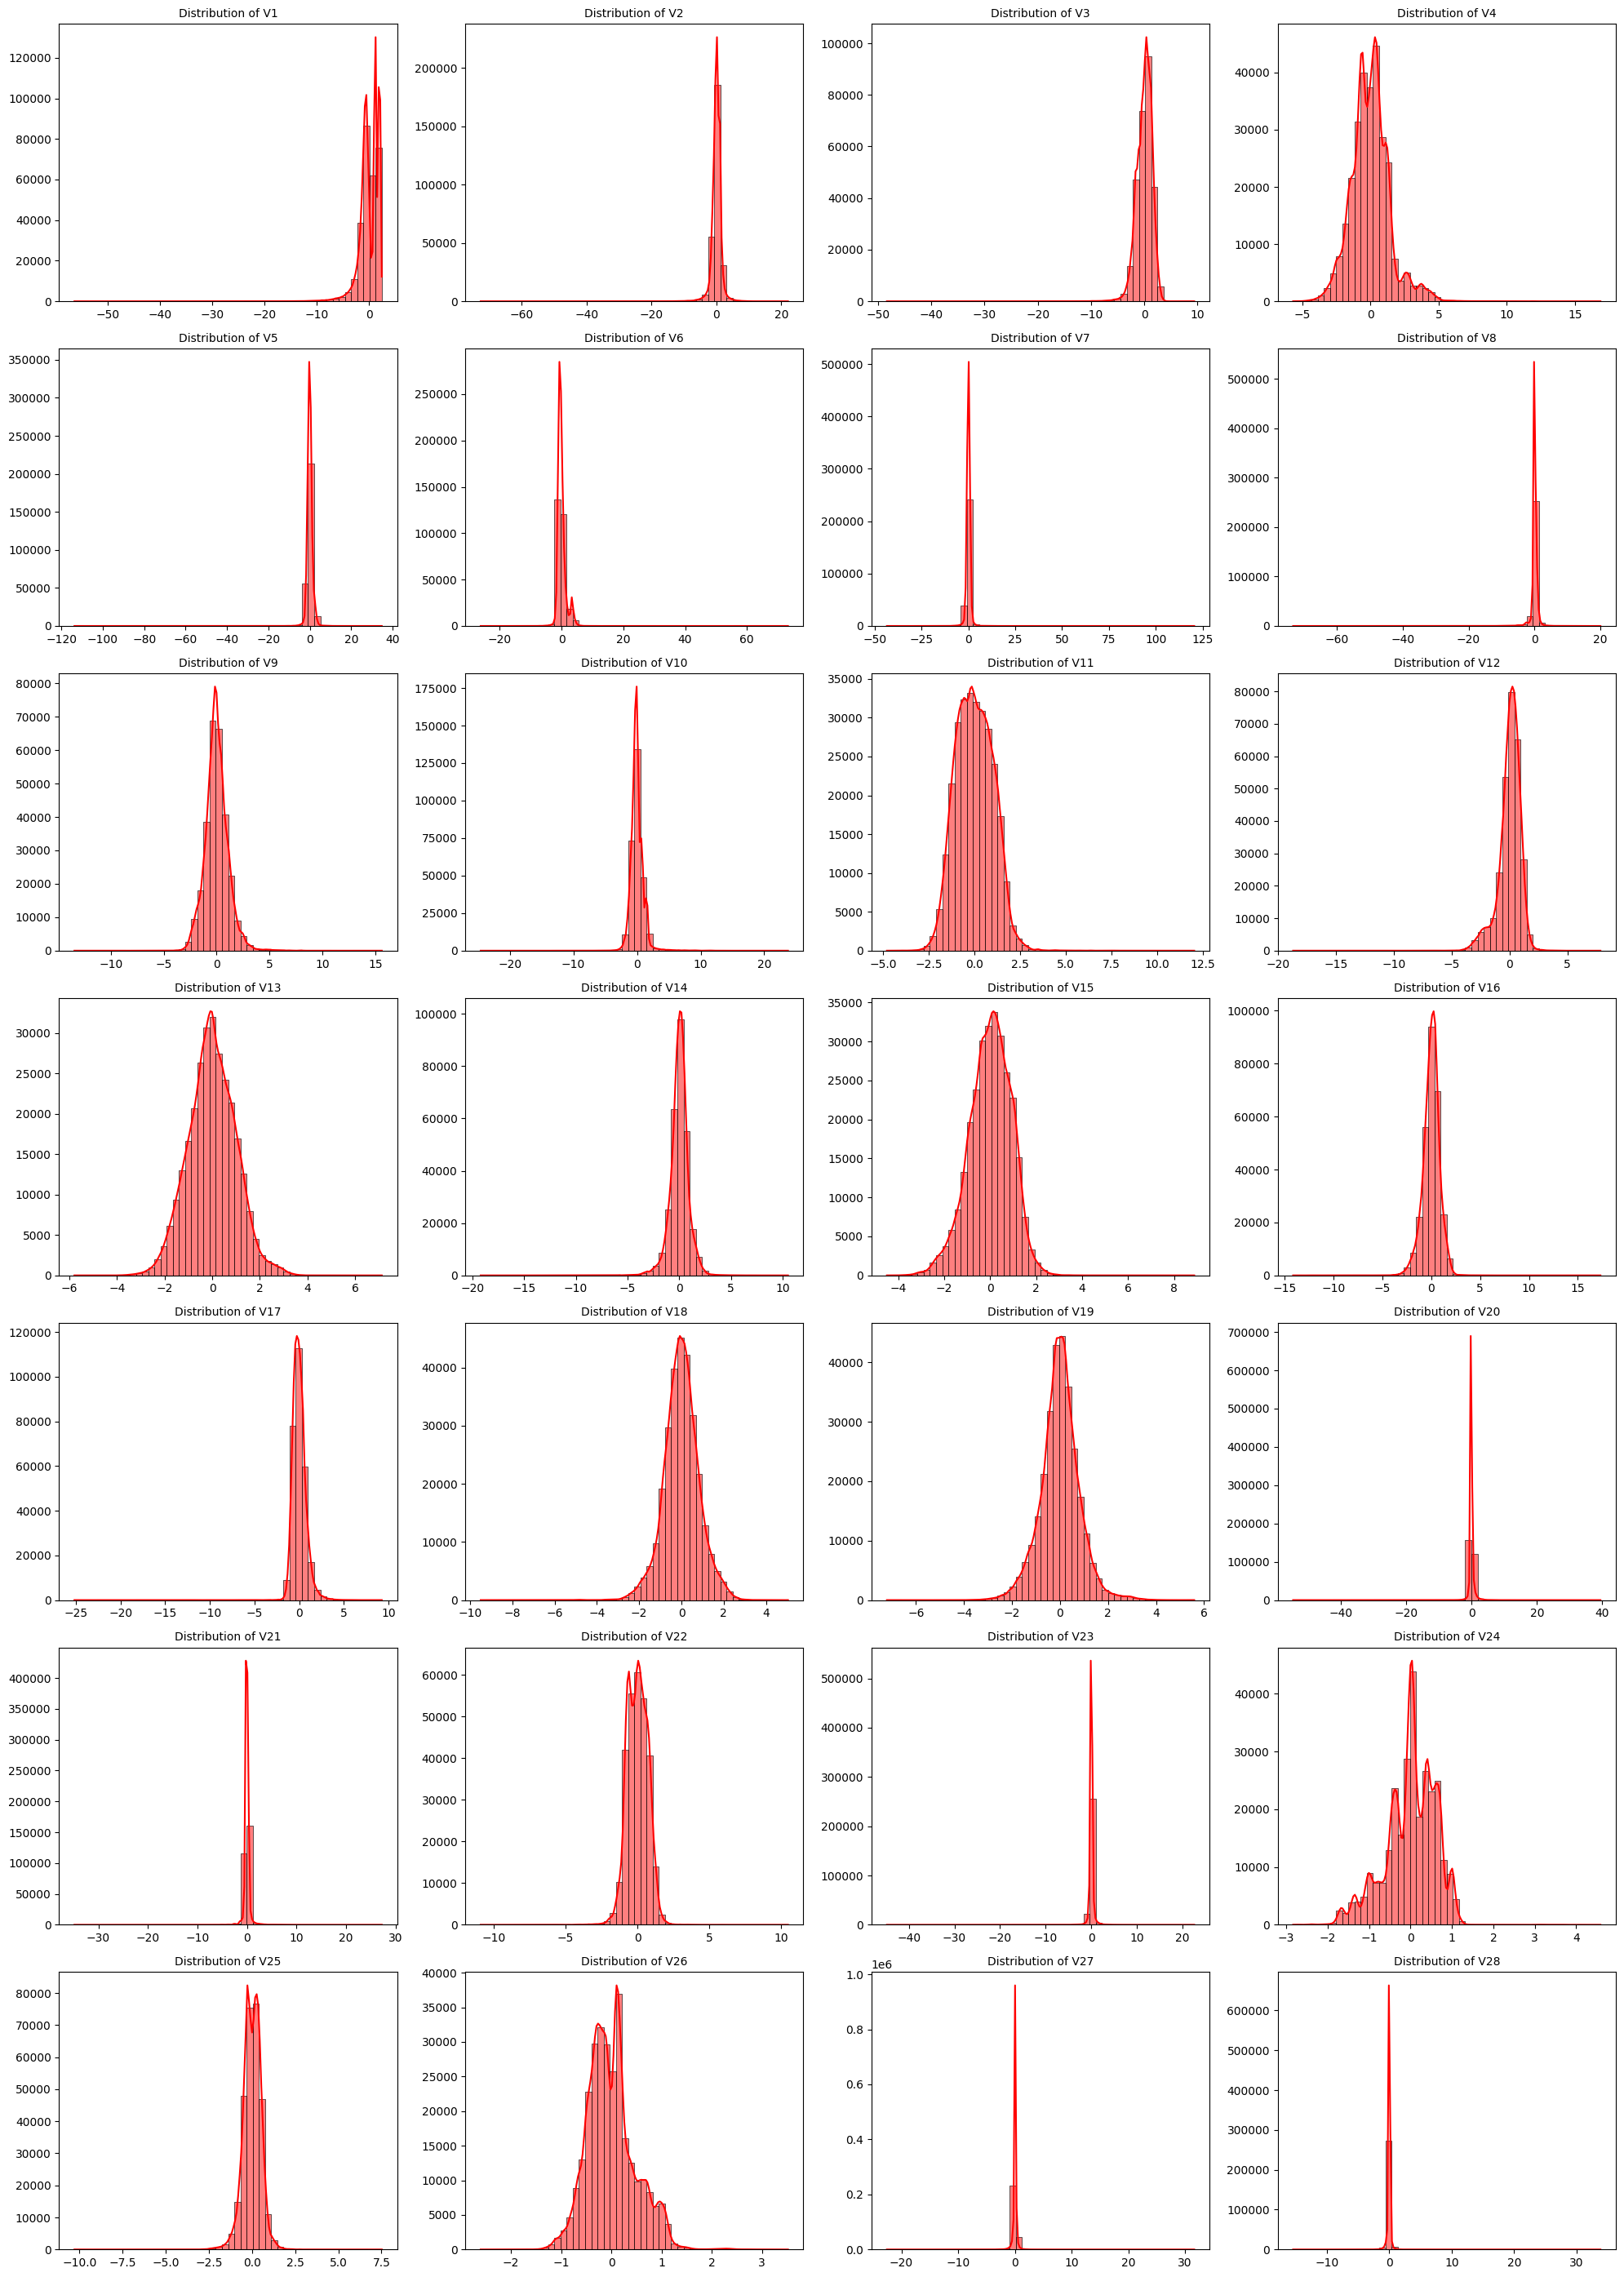

In [ ]:
features = [col for col in df.columns if col not in ['Amount', 'Time', 'Class']]

n_cols = 4
n_rows = (len(features) + n_cols - 1) // n_cols

plt.figure(figsize=(20, 4 * n_rows))
for i, feature in enumerate(features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.histplot(df[feature], bins=50, color='r', kde=True)
    plt.title(f'Distribution of {feature}', fontsize=10)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()


Преобразованные признаки, полученные в результате метода главных компонент (PCA), имеют распределения, преимущественно близкие к нормальному. Большинство из них:

- симметричны с максимумом около нуля,

- имеют единичную дисперсию или близкую к ней,

- демонстрируют отсутствие сильной корреляции, что соответствует целям PCA.

Некоторые признаки (например, V12, V14, V17) имеют узкие или сплюснутые распределения, что может свидетельствовать о низкой вариативности. В то же время другие (такие как V4, V10, V11) демонстрируют тяжёлые хвосты или резкие пики, что может указывать на наличие аномалий, полезных для задач обнаружения мошенничества.



Проверка распределений на нормальность в данном случае не является необходимой.

### Аномалии и выбросы

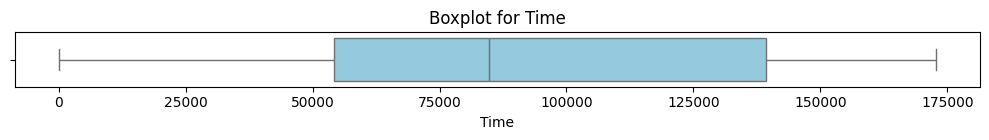

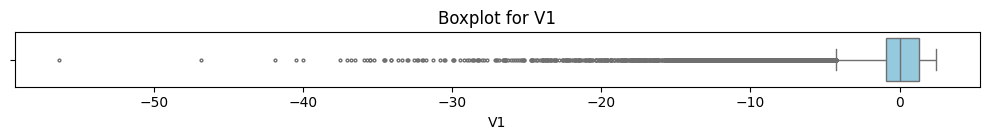

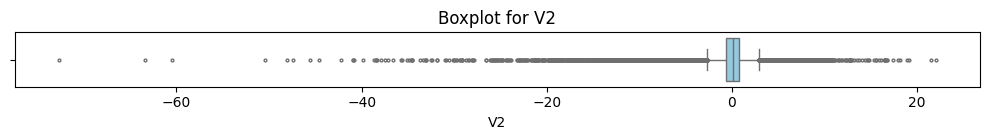

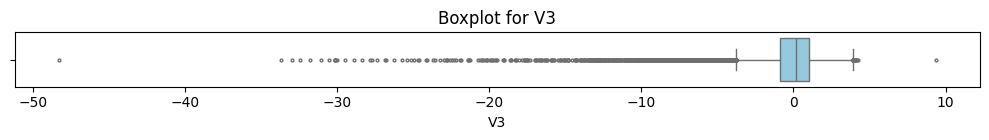

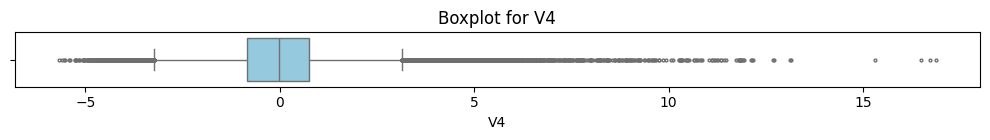

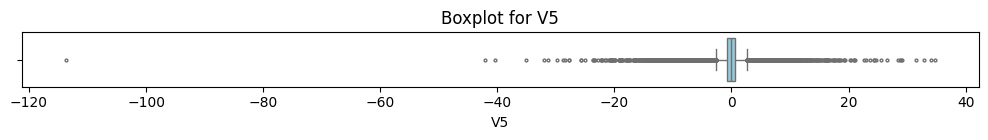

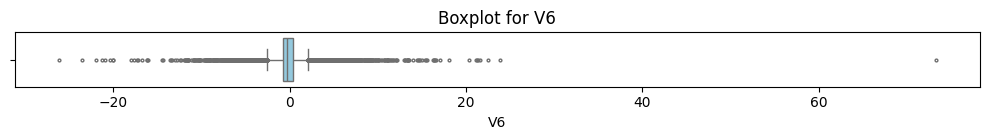

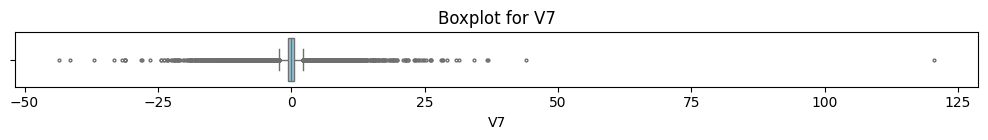

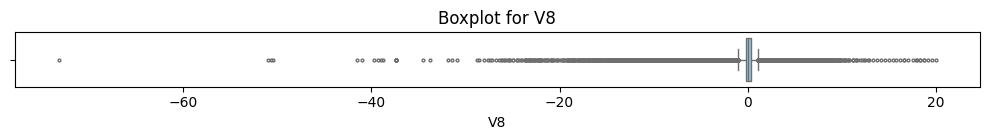

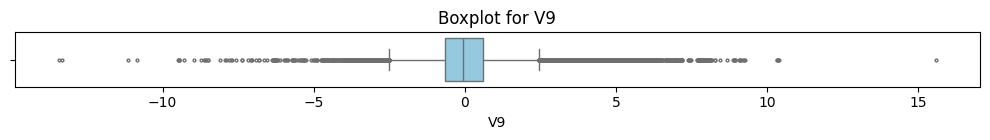

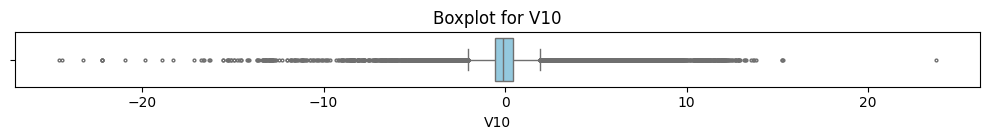

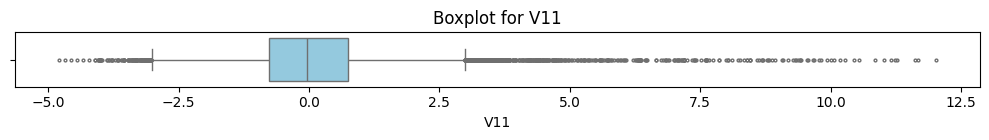

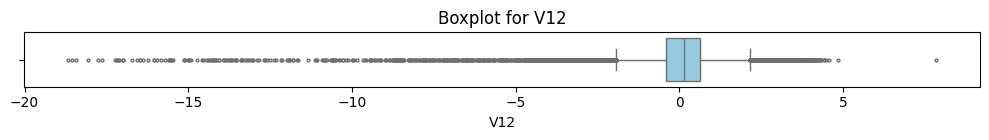

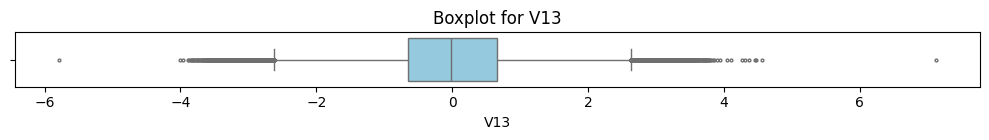

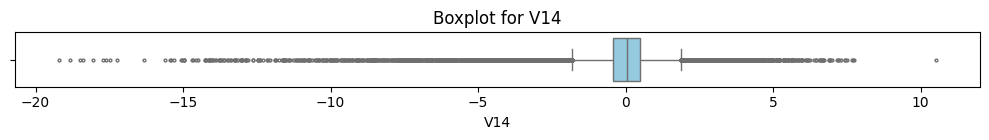

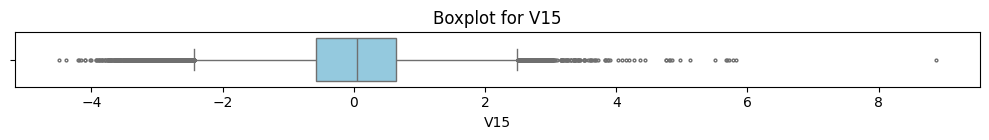

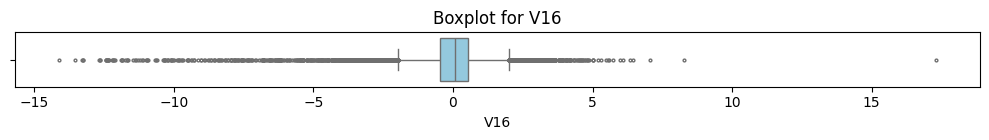

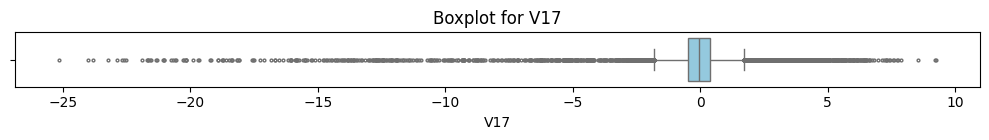

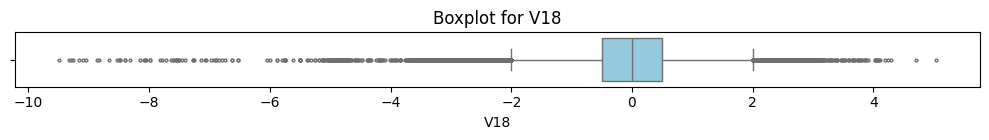

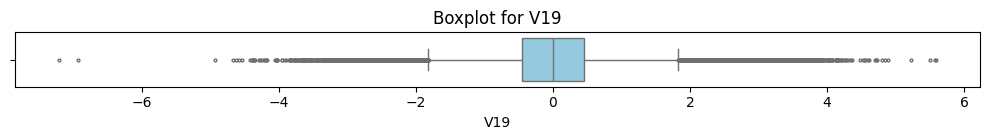

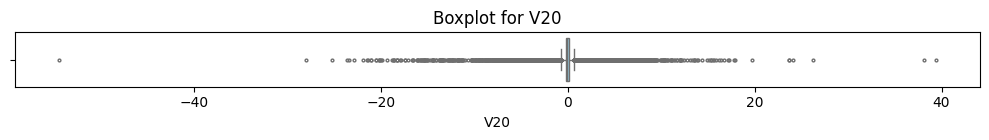

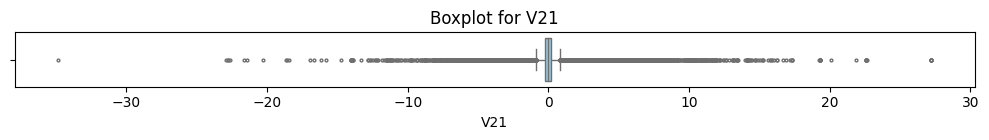

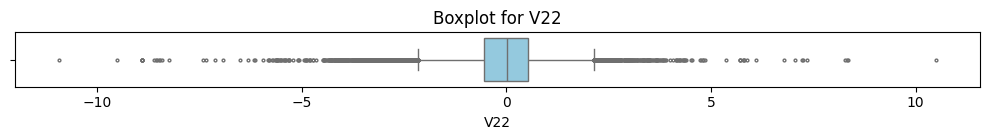

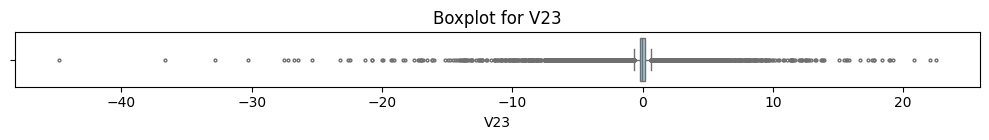

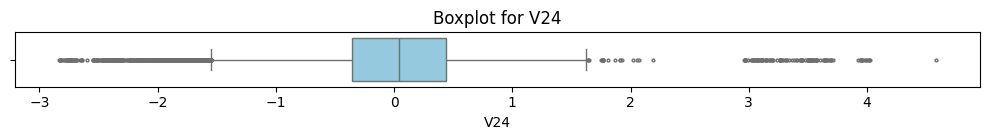

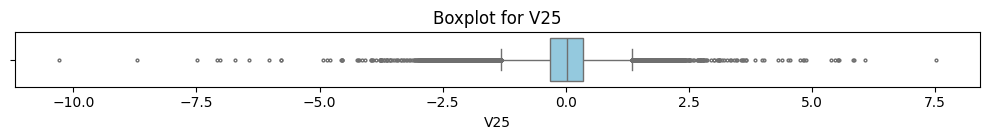

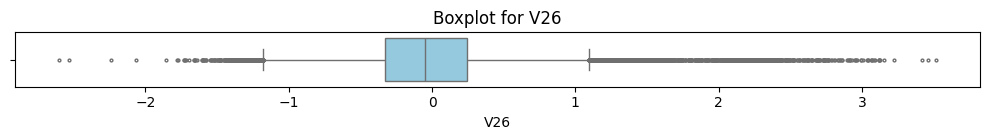

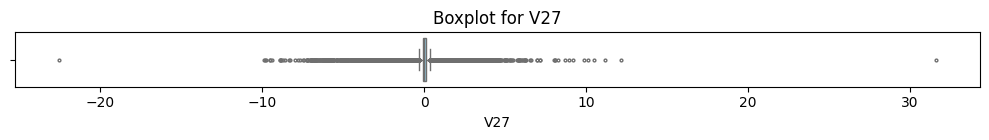

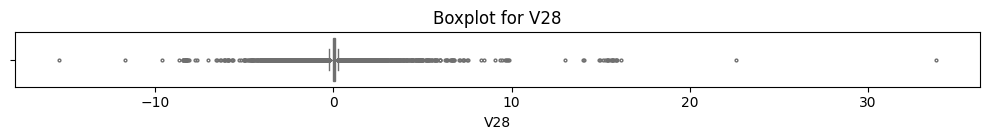

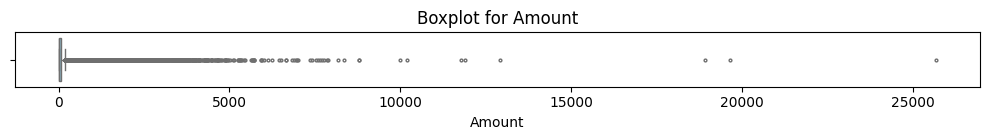

In [ ]:
numeric_columns = df.drop(columns='Class').columns

# Строим boxplot по каждому признаку в отдельных графиках
for col in numeric_columns:
    plt.figure(figsize=(10, 1.5))
    sns.boxplot(x=df[col], color="skyblue", fliersize=2)
    plt.title(f'Boxplot for {col}')
    plt.tight_layout()
    plt.show()

Анализ распределения признаков с помощью boxplot-графиков показал, что в данных действительно присутствуют выбросы. Эти выбросы выражаются в виде точек, значительно выходящих за границы межквартильного размаха.

Однако в контексте задачи обнаружения мошенничества удаление таких выбросов нецелесообразно, поскольку именно аномальные значения часто содержат ключевую информацию о подозрительных или мошеннических транзакциях. Вместо удаления выбросов был выбран подход масштабирования с использованием RobustScaler, позволяющий снизить влияние экстремальных значений, не исключая их из анализа.

### Корреляционный анализ

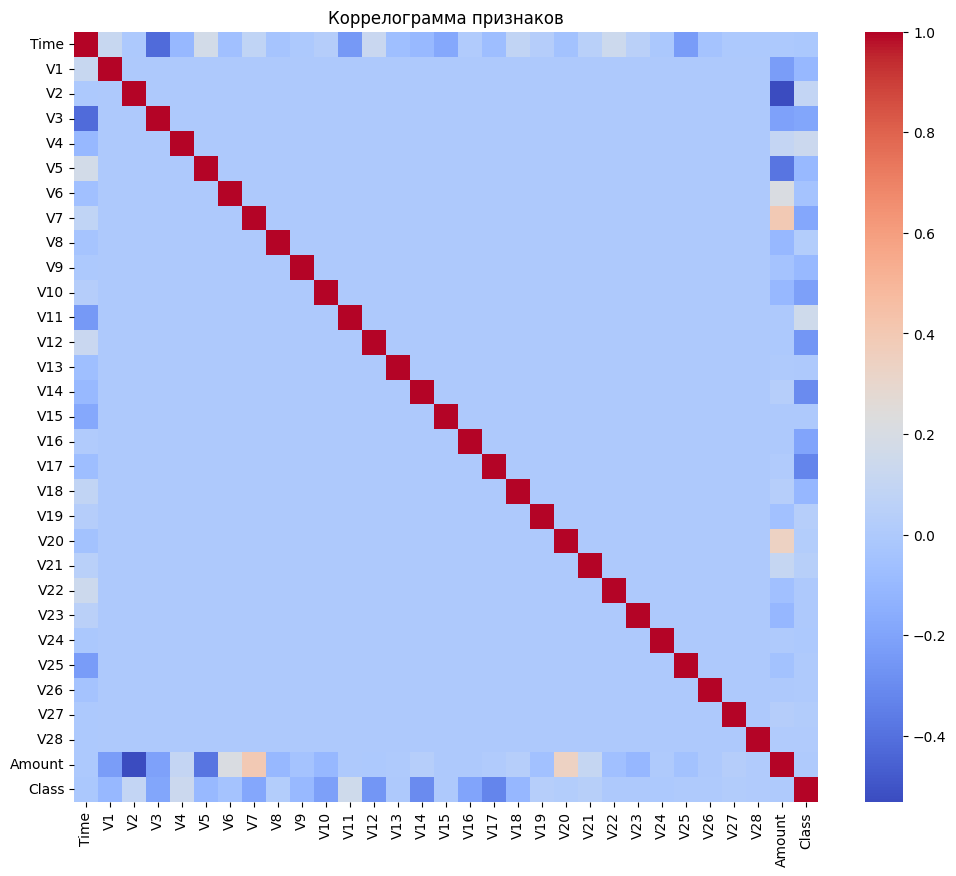

In [ ]:
corr_matrix = df.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title('Коррелограмма признаков')
plt.show()

Анализ взаимосвязей между признаками был проведён с помощью корреляционной матрицы, визуализированной в виде тепловой карты (heatmap). Исходная тепловая карта, построенная на несбалансированной выборке, показывает, что:

- мультиколлинеарность (сильная корреляция между признаками) практически отсутствует, что подтверждает эффективность предварительного преобразования данных с помощью метода главных компонент (PCA);

- признаки Amount и Time демонстрируют умеренную корреляцию с рядом других переменных, в отличие от PCA-признаков;

- целевая переменная Class слабо коррелирует с большинством признаков, а некоторые переменные практически не связаны с ней.

Такой результат можно объяснить сильным дисбалансом классов: редкие случаи мошенничества оказывают минимальное влияние на общее распределение признаков и, соответственно, на значения корреляции.

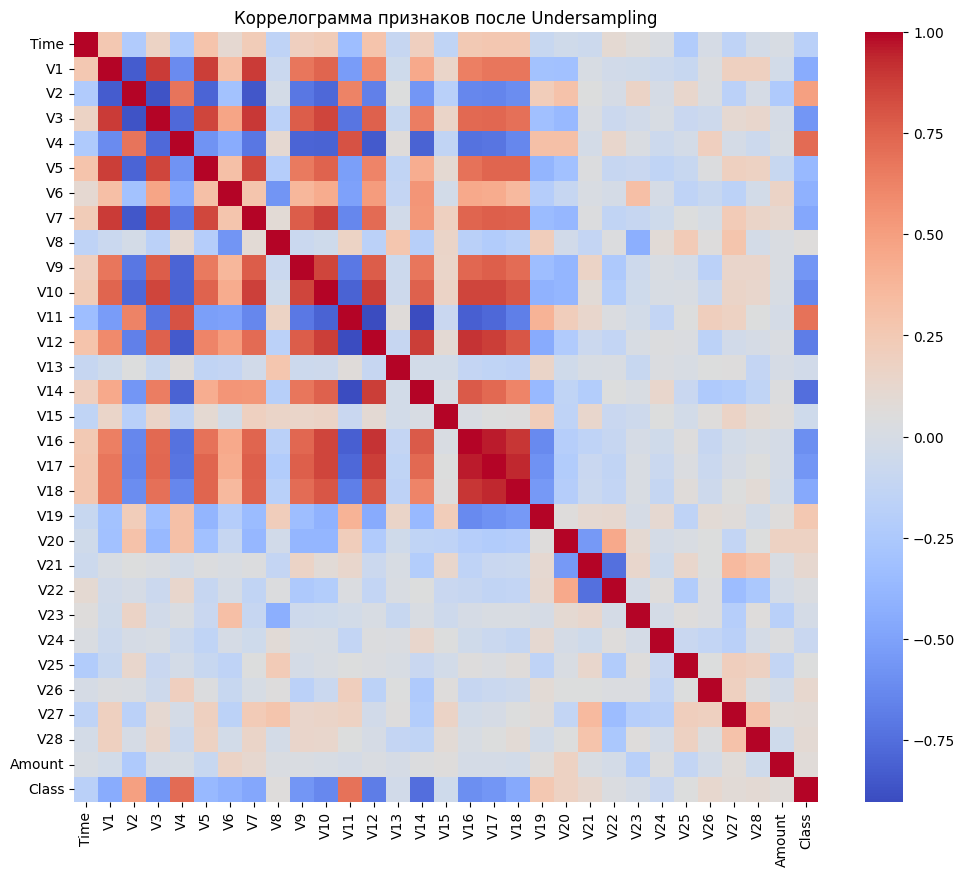

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

X_r_under, y_r_under = RandomUnderSampler(random_state=random_state).fit_resample(df.drop('Class', axis=1), df['Class'])

df_under = pd.concat([X_r_under, y_r_under], axis=1)

corr_matrix = df_under.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title('Коррелограмма признаков после Undersampling')

plt.show()

Для проверки данного предположения данные были сбалансированы методом RandomUnderSampler (подробности приведены далее в разделе 6). После этого корреляционная картина изменилась:

корреляция между признаками и целевой переменной усилилась, что указывает на наличие признаков, потенциально информативных для классификации;

одновременно возникли признаки мультиколлинеарности между некоторыми компонентами, что является типичным побочным эффектом при балансировке данных методом случайного отбора.

Таким образом, корреляционный анализ подтверждает, что дисбаланс классов существенно искажает статистическую картину взаимосвязей, снижая видимость информативных признаков. Однако усиление корреляций после балансировки также требует осторожного подхода, чтобы избежать переобучения или ложных взаимосвязей.

### Совместные распределения признаков с целевой переменной

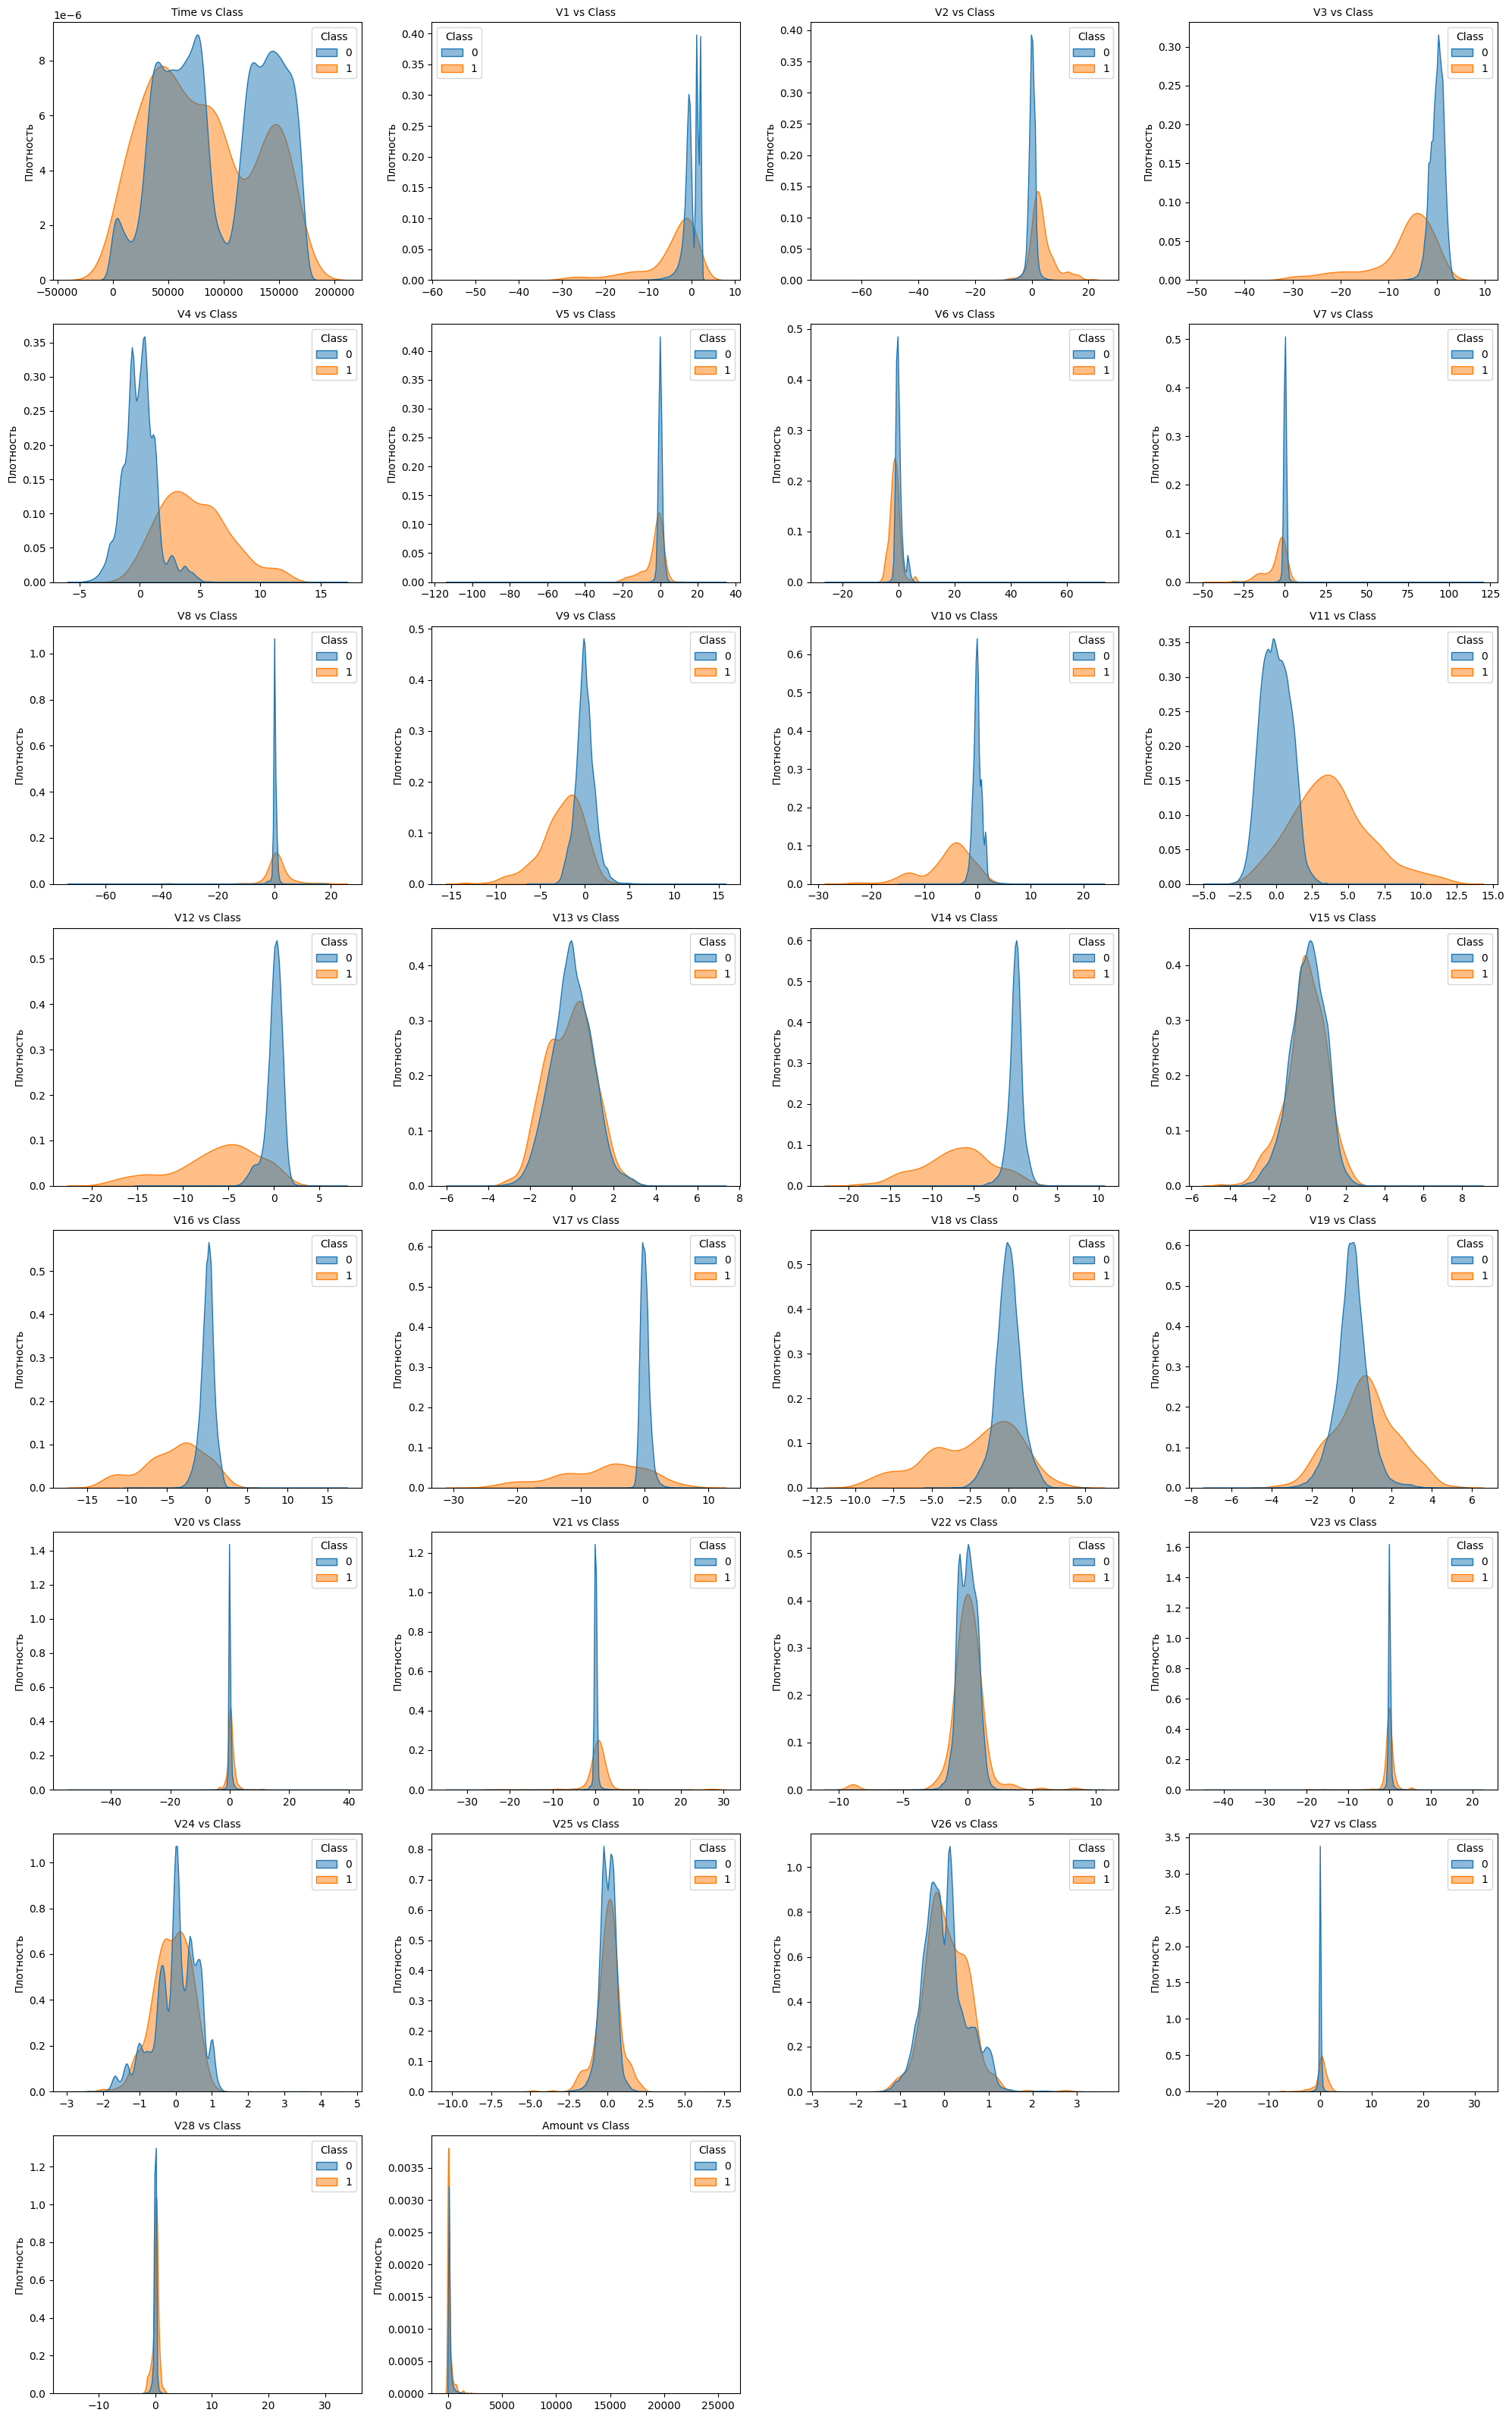

In [ ]:
features = [col for col in df.columns if col != 'Class']

# Определяем размеры сетки для подграфиков
n_cols = 4
n_rows = (len(features) + n_cols - 1) // n_cols

plt.figure(figsize=(20, 4 * n_rows))

# Графики плотности для каждого признака, разделённые по классам
for i, feature in enumerate(features):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.kdeplot(data=df, x=feature, hue='Class', fill=True, common_norm=False, alpha=0.5)
    plt.title(f'{feature} vs Class', fontsize=10)
    plt.xlabel('')
    plt.ylabel('Плотность')

plt.tight_layout()
plt.show()

Для оценки информативности признаков были построены графики совместных распределений (kdeplot) отдельных признаков в разрезе классов (Class = 0 и Class = 1).

Анализ показал, что:

- распределения значений признаков зависят от класса: у многих признаков плотности для мошеннических и легитимных транзакций различаются, что указывает на предсказательную способность этих признаков;

- однако в ряде случаев распределения классов частично перекрываются, что означает, что по отдельности признаки не всегда обеспечивают чёткое разделение между классами.

### Вывод описательного анализа:

Корреляционный анализ и совместные распределения:

Корреляционный анализ и визуализация совместных распределений признаков с целевой переменной показали, что признаки scaled_time, scaled_amount, V8, V13, V15, а также V19–V28 демонстрируют почти нулевую корреляцию с целевым признаком Class, а также схожие распределения для обеих категорий транзакций. Это может указывать на ограниченную индивидуальную предсказательную способность указанных переменных. Тем не менее, поскольку цель работы не включает этап отбора признаков, все переменные сохраняются в последующем анализе для комплексного обучения моделей.

Особенности распределений:

- Признаки V1–V28 обладают распределениями, близкими к нормальному, что соответствует свойствам PCA.

- Признак scaled_time демонстрирует неравномерное распределение, связанное с суточной активностью пользователей.

- Признак scaled_amount имеет выраженную положительную асимметрию, отражающую преобладание мелких транзакций.

Кроме того, во многих признаках были обнаружены выбросы. Однако с учётом специфики задачи (обнаружение аномалий), а также применённого устойчивого масштабирования, удаление или коррекция выбросов не производится и не требуется на текущем этапе.

## 4. Понижение размерности и масштабирование.

Большинство признаков были предварительно масштабированы посредством применения метода главных компонент (PCA), однако признаки Amount и Time не были преобразованы этим методом и, следовательно, находятся в ином масштабе, что может негативно сказаться на обучении моделей, особенно чувствительных к масштабам признаков.

Удаление выбросов в данном случае нецелесообразно, поскольку задача заключается в выявлении аномалий (мошенничества), и именно такие выбросы могут содержать ключевую информацию. Вместо этого важно снизить влияние экстремальных значений, не исключая их из данных.

Для достижения этой цели применяется масштабирование с помощью RobustScaler, который использует медиану и межквартильный размах (IQR), что позволяет привести признаки Amount и Time к сопоставимому масштабу с остальными признаками, при этом снижая влияние выбросов. Такой подход помогает сохранить потенциально значимые аномалии и обеспечить корректную работу алгоритмов машинного обучения, чувствительных к масштабу признаков.

Формула RobustScaler:

$$
X_{\text{scaled}} = \frac{X - Median}{Q_3 - Q_1}
$$
где:
- Q₁ — первый квартиль (25-й перцентиль)
- Q₃ — третий квартиль (75-й перцентиль)
- Q₃ − Q₁ — межквартильный размах (IQR)


In [ ]:
from sklearn.preprocessing import RobustScaler

rob_scaler = RobustScaler()

scaled_amount = rob_scaler.fit_transform(df['Amount'].values.reshape(-1,1))
scaled_time = rob_scaler.fit_transform(df['Time'].values.reshape(-1,1))

df.drop(['Time','Amount'], axis=1, inplace=True)

df.insert(0, 'scaled_amount', scaled_amount)
df.insert(1, 'scaled_time', scaled_time)

df.head()

,scaled_amount,scaled_time,V1,V2,V3,V4,V5,V6,V7,V8,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,1.783274,-0.994983,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0
1,-0.269825,-0.994983,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0
2,4.983721,-0.994972,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0
3,1.418291,-0.994972,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0
4,0.670579,-0.994960,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0


## 5. Методы обучения без учителя

### Понижение размерности

Поскольку признаки V1–V28, представленные в датасете, уже являются результатом предварительного применения метода главных компонент (PCA), проведение повторного понижения размерности нецелесообразно. Это может привести к искажению уже оптимизированного признакового пространства и потенциальной потере информации, особенно значимой для выявления редких и аномальных наблюдений.

### Кластерный анализ

Для проведения предварительного анализа структуры данных применим кластерный анализ, цель которого — выявить скрытую группировку транзакций, потенциально отражающую различие между нормальным и мошенническим поведением. Поскольку кластеризация осуществляется без использования целевых меток (Class), она позволяет оценить, существуют ли в пространстве признаков естественно формирующиеся плотные регионы и как они соотносятся с целевыми значениями. Такой подход помогает проверить гипотезу о геометрической разделимости классов, что критично для последующего применения моделей машинного обучения.

В качестве алгоритма кластеризации выбран K-Means как вычислительно эффективный, интерпретируемый и хорошо масштабируемый метод, применимый к большим выборкам. Его предпосылки — наличие сферических, равноразмерных кластеров и использование евклидовой метрики — соответствуют особенностям представленного датасета.

Для количественной оценки качества кластеризации использовался индекс Калинского–Харабаса (Calinski–Harabasz Score) — метрика, характеризующая соотношение межкластерной и внутрикластерной дисперсий. В отличие от силуэтного коэффициента, который имеет квадратичную сложность, данный индекс вычисляется значительно быстрее и позволяет объективно сравнивать модели с разным числом кластеров. Чем выше значение Calinski–Harabasz Score, тем более чётко выражена кластерная структура.

Перед выполнением кластеризации все признаки предварительно масштабируются с использованием RobustScaler, поскольку они имеют разные шкалы измерения. Без приведения всех признаков к сопоставимому масштабу расстояния между точками, используемые в большинстве алгоритмов кластеризации, теряют смысл: признаки с большей шкалой начинают доминировать над остальными, и модель будет искажённо интерпретировать структуру данных.

K-means started with k=2
K-means started with k=3
K-means started with k=4
K-means started with k=5
K-means started with k=6
K-means started with k=7
K-means started with k=8
K-means started with k=9
K-means started with k=10


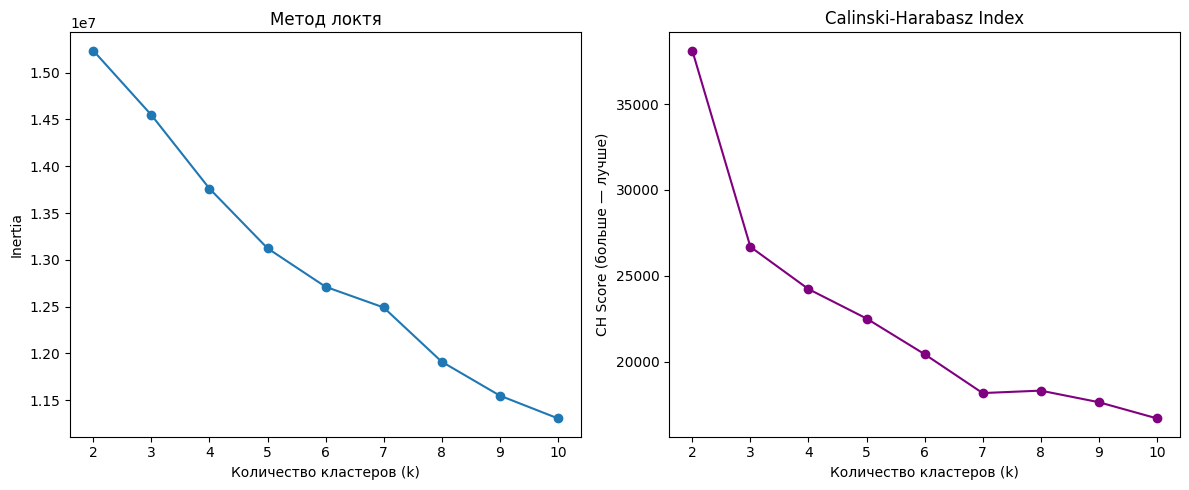

In [ ]:
inertias = []
ch_scores = []
k_range = range(2, 11)

# отдельный датасет, так как возможно далее попробуем обучить модели с меткой кластера
df_cluster = df.copy()

X = RobustScaler().fit_transform(df_cluster.drop(columns=["Class"]))

for k in k_range:
    print(f'K-means started with k={k}')
    kmeans = KMeans(n_clusters=k, random_state=random_state)
    labels = kmeans.fit_predict(X)
    inertias.append(kmeans.inertia_)
    ch_scores.append(calinski_harabasz_score(X, labels))

# Графики
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_range, inertias, marker='o')
plt.title("Метод локтя")
plt.xlabel("Количество кластеров (k)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(k_range, ch_scores, marker='o', color='purple')
plt.title("Calinski-Harabasz Index")
plt.xlabel("Количество кластеров (k)")
plt.ylabel("CH Score (больше — лучше)")

plt.tight_layout()
plt.show()

Для определения оптимального числа кластеров были построены графики зависимости внутрикластерной дисперсии (inertia) и индекса Калинского–Харабаса (Calinski–Harabasz Score) от количества кластеров k в диапазоне от 2 до 10. Метод локтя, основанный на анализе дисперсии, показал плавное и равномерное снижение inertia без выраженной точки изгиба, что затрудняет однозначный выбор k.

В то же время, метрика Calinski–Harabasz, отражающая отношение межкластерной дисперсии к внутрикластерной, достигла максимального значения при k = 2, после чего резко снизилась. Это указывает на то, что при двух кластерах данные разделяются на наиболее чётко выраженные и компактные группы. Поскольку данный индекс напрямую измеряет качество кластерной структуры и обладает высокой вычислительной эффективностью, он был выбран в качестве основного критерия для выбора числа кластеров.

Таким образом, значение k = 2 было признано оптимальным: оно обеспечивает наилучшее разделение данных с точки зрения внутригрупповой плотности и межгрупповой разобщённости, при этом соответствует естественному бинарному характеру задачи (мошенничество / не мошенничество).

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=random_state)
cluster_labels = kmeans.fit_predict(X)

# Добавим метки кластеров в копию датасета
df_cluster["Cluster"] = cluster_labels

In [ ]:
# Таблица: сколько объектов из каждого класса в каждом кластере
cluster_vs_class = pd.crosstab(df_cluster["Cluster"], df_cluster["Class"])
cluster_vs_class_sorted = cluster_vs_class.sort_values(by=1, ascending=False)
cluster_vs_class_sorted['%'] = cluster_vs_class_sorted[1] / (cluster_vs_class_sorted[0] + cluster_vs_class_sorted[1]) * 100

print("Сравнение кластеров с мошенничеством (отсортировано по количеству Class=1):")
display(cluster_vs_class_sorted)

Сравнение кластеров с мошенничеством (отсортировано по количеству Class=1):


Class,0,1,%
Cluster,,,
0,279121,474,0.169531
1,5194,18,0.345357


При кластеризации с числом кластеров k = 2 большинство транзакций оказалось сгруппировано в кластер 0, который включает 279 121 обычную транзакцию и 474 случая мошенничества. Второй кластер значительно меньше по размеру (всего около 5 000 наблюдений), но в относительном выражении содержит в два раза больше мошеннических транзакций (0.34% против 0.17%).

Это свидетельствует о том, что, несмотря на отсутствие чёткой сегрегации фрода, кластеризация выявила регион признакового пространства с повышенной концентрацией аномалий, что подтверждает частичную геометрическую разделимость классов. Такой результат можно интерпретировать как предварительное доказательство существования структурных различий между типичными и атипичными транзакциями.

## 6. Деление выборки и подходы к устранению дисбаланса классов (data-level)

Для начала разделим данные на обучающую и тестовую выборки без применения каких-либо методов устранения дисбаланса классов. Это необходимо для того, чтобы впоследствии объективно оценить влияние балансировки на качество моделей.

Разделение осуществляется случайным образом, поскольку в задаче обнаружения мошеннических транзакций отсутствует временная зависимость или тренд. Несмотря на наличие признака Time, транзакции в датасете не связаны между собой логически или поведенчески, и их порядок не несёт дополнительной информации. В связи с этим нет необходимости использовать временную кросс-валидацию или time series split.

В работе использовано классическое соотношение:
- 80 % — обучающая выборка
- 20 % — тестовая выборка

что позволяет обеспечить как достаточный объём данных для обучения модели, так и репрезентативность тестирования.

In [ ]:
X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=random_state)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nРаспределение классов в обучающей выборке:")
print(y_train.value_counts(normalize=True))

print("\nРаспределение классов в тестовой выборке:")
print(y_test.value_counts(normalize=True))

Размер обучающей выборки: (227845, 30)
Размер тестовой выборки: (56962, 30)

Распределение классов в обучающей выборке:
Class
0    0.998271
1    0.001729
Name: proportion, dtype: float64

Распределение классов в тестовой выборке:
Class
0    0.99828
1    0.00172
Name: proportion, dtype: float64


С использованием стандартной функции train_test_split из библиотеки sklearn.model_selection датасет был разделён на обучающую и тестовую выборки. Для сохранения исходных пропорций между классами при разделении использовался параметр stratify=y, благодаря чему дисбаланс классов сохранился в обеих выборках и остался сопоставимым с распределением в полном наборе данных.

Таким образом, прежде чем перейти к построению моделей, необходимо рассмотреть методы борьбы с дисбалансом классов на уровне данных (data-level), направленные на увеличение представления миноритарного класса и улучшение качества классификации.

### Методы уменьшения выборки - Undersampling

Метод уменьшения выборки (undersampling) заключается в сокращении числа наблюдений мажоритарного класса с целью достижения баланса между классами в обучающей выборке. Такой подход позволяет снизить влияние доминирующего класса на процесс обучения и тем самым повысить чувствительность модели к редким и аномальным наблюдениям миноритарного класса.

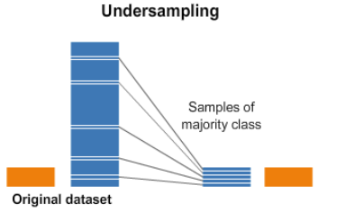

Random Undersampling — один из простейших методов балансировки выборки, заключающийся в случайном удалении части наблюдений мажоритарного класса.

Реализуется с помощью метода RandomUnderSampler из библиотеки imbalanced-learn.

Важно заметить, что методы балансировки классов, такие как oversampling и undersampling, применяются исключительно к обучающей выборке. Это обусловлено тем, что тестовая выборка должна отражать реальное распределение классов в данных, чтобы обеспечить объективную и корректную оценку качества модели в условиях, максимально приближенных к реальному применению. Искусственное изменение структуры тестовых данных может привести к искажённым результатам и завышенной оценке производительности модели.

In [ ]:
from imblearn.under_sampling import RandomUnderSampler

X_train_r_under, y_train_r_under = RandomUnderSampler(random_state=random_state).fit_resample(X_train, y_train)

print("Размер обучающей выборки (RandomUnderSampler):", X_train_r_under.shape)
print("Распределение классов после undersampling (RandomUnderSampler):")
display(y_train_r_under.value_counts(normalize=True))
print(f"Undersampling удалил {X_train.shape[0] - X_train_r_under.shape[0]} строк, что составляет {(X_train.shape[0] - X_train_r_under.shape[0])/X_train.shape[0]*100:.2f}% исходной обучающей выборки.")

Размер обучающей выборки (RandomUnderSampler): (788, 30)
Распределение классов после undersampling (RandomUnderSampler):


,proportion
Class,
0,0.5
1,0.5


Undersampling удалил 227057 строк, что составляет 99.65% исходной обучающей выборки.


В результате можно наблюдать, что классы в обучающей выборке стали сбалансированными. Однако метод уменьшения выборки (undersampling) существенно сокращает общий объём обучающих данных, что является его основным недостатком. Более того, случайный характер отбора примеров мажорного класса метода RandomUnderSampler может привести к потере значимой информации и, как следствие, к снижению качества обобщения модели. Это может негативно сказаться на её способности делать точные предсказания на реальных, несбалансированных тестовых данных.

Проблему потенциальной необъективности случайного отбора при уменьшении выборки можно частично решить с помощью алгоритмов, основанных на расстоянии:

NearMiss – семейство методов, отбирающих подмножество большинства, которое находится ближе всего к миноритарным точкам, то есть фокусируется на тех образцах большинства, которые труднее всего классифицировать:

- NearMiss version=1 (по умолчанию) - Cохраняет объекты мажоритарного класса, имеющие наименьшее среднее расстояние до ближайших объектов меньшинства

- NearMiss version=2 - Cохраняет объекты большинства, имеющие наименьшее среднее расстояние до всех объектов меньшинства (Хорошо подходит при небольшой выборке)

- NearMiss version=3 - Для каждого объекта меньшинства выбирает объекты большинства с наименьшим расстоянием к нему (Лучше покрывает локальные окрестности меньшинства)

In [ ]:
from imblearn.under_sampling import NearMiss

X_train_nm, y_train_nm = NearMiss().fit_resample(X_train, y_train)

print("Размер обучающей выборки (NearMiss version=1):", X_train_nm.shape)
print("Распределение классов после undersampling (NearMiss version=1):")
display(y_train_nm.value_counts(normalize=True))
print(f"NearMiss удалил {X_train.shape[0] - X_train_nm.shape[0]} строк, что составляет {(X_train.shape[0] - X_train_nm.shape[0]) / X_train.shape[0] * 100:.2f}% исходной обучающей выборки.")

Размер обучающей выборки (NearMiss version=1): (788, 30)
Распределение классов после undersampling (NearMiss version=1):


,proportion
Class,
0,0.5
1,0.5


NearMiss удалил 227057 строк, что составляет 99.65% исходной обучающей выборки.


In [ ]:
X_train_nm2, y_train_nm2 = NearMiss(version=2).fit_resample(X_train, y_train)

print("Размер обучающей выборки (NearMiss version=2):", X_train_nm2.shape)
print("Распределение классов после undersampling (NearMiss version=2):")
display(y_train_nm2.value_counts(normalize=True))
print(f"NearMiss удалил {X_train.shape[0] - X_train_nm2.shape[0]} строк, что составляет {(X_train.shape[0] - X_train_nm2.shape[0]) / X_train.shape[0] * 100:.2f}% исходной обучающей выборки.")

Размер обучающей выборки (NearMiss version=2): (788, 30)
Распределение классов после undersampling (NearMiss version=2):


,proportion
Class,
0,0.5
1,0.5


NearMiss удалил 227057 строк, что составляет 99.65% исходной обучающей выборки.


In [ ]:
X_train_nm3, y_train_nm3 = NearMiss(version=3).fit_resample(X_train, y_train)

print("Размер обучающей выборки (NearMiss version=3):", X_train_nm3.shape)
print("Распределение классов после undersampling (NearMiss version=3):")
display(y_train_nm3.value_counts(normalize=True))
print(f"NearMiss удалил {X_train.shape[0] - X_train_nm3.shape[0]} строк, что составляет {(X_train.shape[0] - X_train_nm3.shape[0]) / X_train.shape[0] * 100:.2f}% исходной обучающей выборки.")

Размер обучающей выборки (NearMiss version=3): (737, 30)
Распределение классов после undersampling (NearMiss version=3):


/usr/local/lib/python3.11/dist-packages/imblearn/under_sampling/_prototype_selection/_nearmiss.py:206: UserWarning: The number of the samples to be selected is larger than the number of samples available. The balancing ratio cannot be ensure and all samples will be returned.
  warnings.warn(


,proportion
Class,
1,0.5346
0,0.4654


NearMiss удалил 227108 строк, что составляет 99.68% исходной обучающей выборки.


Cluster Centroids – сжатие большинства до нескольких кластерных центроидов. Мажоритарный класс кластеризуется (например, k-means), и вместо всех точек оставляются центроиды кластеров как представительные примеры. Это уменьшает размер выборки, усредняя схожие объекты.

In [ ]:
from imblearn.under_sampling import ClusterCentroids

X_train_cc, y_train_cc = ClusterCentroids(random_state=random_state).fit_resample(X_train, y_train)

print("Размер обучающей выборки (Cluster Centroids):", X_train_cc.shape)
print("Распределение классов после применения Cluster Centroids:")
display(y_train_cc.value_counts(normalize=True))
print(f"Cluster Centroids удалил {X_train.shape[0] - X_train_cc.shape[0]} строк, это {(X_train.shape[0] - X_train_cc.shape[0]) / X_train.shape[0] * 100:.2f}% исходной обучающей выборки.")


Размер обучающей выборки (Cluster Centroids): (788, 30)
Распределение классов после применения Cluster Centroids:


,proportion
Class,
0,0.5
1,0.5


Cluster Centroids удалил 227057 строк, это 99.65% исходной обучающей выборки.


Достоинства undersampling: значительно сокращает объем данных, ускоряет обучение. Удаляя дублирующие или далеко от границ лежащие примеры большинства, можно снизить смещение классификатора и заставить его фокусироваться на важных, “сложных” для разделения областях. Кроме того, undersampling хорошо сочетается с ансамблевыми методами (например, построение нескольких моделей на разных подвыборках большинства).

Недостатки undersampling: самое очевидное – потеря части информации. Если выборка большинства недостаточно покрывает все вариации класса, удаление данных может упростить задачу до состояния, когда модель не увидит важных примеров нормального класса и может переобучиться на меньшинство. Также при экстремальном дисбалансе (например, 1000:1) удаление 90–99% данных большинства ради баланса может быть нецелесообразным – лучше прибегнуть к увеличению меньшинства. Поэтому часто undersampling применяют аккуратно или в комбинации с другими методами.

### Методы увеличения выборки - Oversampling

Метод увеличения выборки (oversampling) направлен на искусственное увеличение числа примеров минорного класса, чтобы сбалансировать его по отношению к мажорному. Это позволяет усилить представление редких классов в обучающем процессе и повысить точность модели при их распознавании.

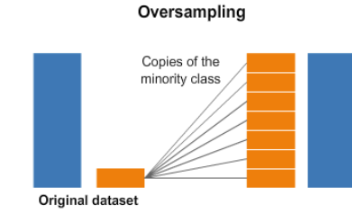

Одним из наиболее простых подходов к увеличению числа примеров минорного класса является случайное дублирование наблюдений. Метод RandomOverSampler из библиотеки imbalanced-learn реализует этот подход, случайным образом повторяя экземпляры минорного класса до достижения балансировки с мажорным классом.

In [ ]:
from imblearn.over_sampling import RandomOverSampler

X_train_r_over, y_train_r_over = RandomOverSampler(random_state=random_state).fit_resample(X_train, y_train)

print("Размер обучающей выборки (RandomOverSampler):", X_train_r_over.shape)
print("Распределение классов после oversampling (RandomOverSampler):")
display(y_train_r_over.value_counts(normalize=True))
print(f"RandomOversampling добавил {X_train_r_over.shape[0] - X_train.shape[0]} строк, что составляет {(X_train_r_over.shape[0] - X_train.shape[0]) / X_train.shape[0] * 100:.2f}% прироста к исходной обучающей выборке.")


Размер обучающей выборки (RandomOverSampler): (454902, 30)
Распределение классов после oversampling (RandomOverSampler):


,proportion
Class,
0,0.5
1,0.5


RandomOversampling добавил 227057 строк, что составляет 99.65% прироста к исходной обучающей выборке.


В результате применения метода RandomOversampler наблюдается балансировка классов в обучающей выборке за счет искусственного увеличения числа наблюдений минорного класса. Главным его преимуществом является простота реализации, однако данный метод может привести к переобучению за счет повторения одних и тех же примеров.

Более продвинутый и широко используемый метод – SMOTE (Synthetic Minority Over-sampling Technique), который синтетически генерирует новые объекты минорного класса, интерполируя между ближайшими соседями. Он генерирует синтетические образцы внутри пространств между соседними миноритарными точками, что увеличивает разнообразие новых данных. Этот метод значительно улучшает представление меньшинства без простого дублирования, но имеет ограничения: может случайно породить нерепрезентативные или дублирующиеся примеры и игнорирует распределение исходных данных. Также SMOTE не учитывает потенциальный шум и выбросы – может усиливать их.

In [ ]:
from imblearn.over_sampling import SMOTE

X_train_sm, y_train_sm = SMOTE(random_state=random_state).fit_resample(X_train, y_train)

print("Размер обучающей выборки (SMOTE):", X_train_sm.shape)
print("Распределение классов после oversampling (SMOTE):")
display(y_train_sm.value_counts(normalize=True))
print(f"SMOTE добавил {X_train_sm.shape[0] - X_train.shape[0]} строк, что составляет {(X_train_sm.shape[0] - X_train.shape[0]) / X_train.shape[0] * 100:.2f}% прироста к исходной обучающей выборке.")


Размер обучающей выборки (SMOTE): (454902, 30)
Распределение классов после oversampling (SMOTE):


,proportion
Class,
0,0.5
1,0.5


SMOTE добавил 227057 строк, что составляет 99.65% прироста к исходной обучающей выборке.


Однако есть еще более продвинутый метод:

ADASYN (Adaptive Synthetic Sampling) – адаптивный вариант SMOTE, генерирующий больше синтетических точек в областях, где миноритарный класс особенно редок или сложен для классификации. Идея ADASYN – сместить фокус генерации к трудным областям, улучшая локальное распознавание сложных случаев.

In [ ]:
from imblearn.over_sampling import ADASYN

adasyn = ADASYN(random_state=random_state)
X_train_ad, y_train_ad = adasyn.fit_resample(X_train, y_train)

print("Размер обучающей выборки (ADASYN):", X_train_ad.shape)
print("Распределение классов после oversampling (ADASYN):")
display(y_train_ad.value_counts(normalize=True))
print(f"ADASYN добавил {X_train_ad.shape[0] - X_train.shape[0]} строк, что составляет {(X_train_ad.shape[0] - X_train.shape[0]) / X_train.shape[0] * 100:.2f}% прироста к исходной обучающей выборке.")


Размер обучающей выборки (ADASYN): (454885, 30)
Распределение классов после oversampling (ADASYN):


,proportion
Class,
0,0.500019
1,0.499981


ADASYN добавил 227040 строк, что составляет 99.65% прироста к исходной обучающей выборке.


В результате применения ADASYN наблюдается создание большего числа синтетических наблюдений по сравнению со SMOTE, что обусловлено адаптивным распределением синтетических примеров в зависимости от локальной сложности классификации.

На сегодняшний день существует множество других вариаций и усовершенствований метода SMOTE, направленных на устранение его ограничений — таких как генерация шумов, игнорирование структуры данных или работа с категориальными признаками. К ним относятся, например, Borderline-SMOTE, SMOTE-NC, ADASYN, SVM-SMOTE, KMeans-SMOTE и другие.
Однако, учитывая объём и цели данной работы, подробное рассмотрение всех модификаций SMOTE выходит за рамки курсового проекта. Поэтому для анализа выбраны наиболее показательные и практически применимые версии, демонстрирующие основные принципы и эффективность подхода.

GAN-oversampling – современные исследования применяют генеративно-состязательные сети (GAN) для порождения новых примеров минорного класса. GAN обучается на реальных данных и генерирует синтетические образцы, имитирующие распределение меньшинства. Это особенно перспективно в задачах с сложной структурой данных (изображения, тексты).

GAN состоит из двух нейросетей:

Генератора, который учится создавать фейковые примеры, имитирующие распределение настоящих данных;

Дискриминатора, который учится отличать реальные данные от синтетических.

Обе модели обучаются одновременно в рамках состязательного процесса. Генератор стремится обмануть дискриминатор, в то время как дискриминатор пытается правильно различить подлинные и поддельные примеры. Этот подход позволяет генератору научиться создавать реалистичные данные, близкие по распределению к данным миноритарного класса, что делает его перспективным средством oversampling.

В данной работе GAN применяется для генерации дополнительных объектов миноритарного класса на основе его существующего поднабора, с целью выравнивания баланса классов в обучающей выборке. В отличие от методов типа SMOTE, GAN способен моделировать более сложные зависимости между признаками и создавать примеры, которые не являются просто линейной комбинацией существующих точек.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
import tensorflow as tf

class GAN(BaseEstimator, TransformerMixin):
    def __init__(self, latent_dim=32, epochs=1000, batch_size=64, verbose=False):
        """
        latent_dim — размерность латентного (скрытого) пространства, из которого генерируются данные
        epochs — количество эпох обучения GAN
        batch_size — размер батча
        verbose — режим вывода подробной информации
        """
        self.latent_dim = latent_dim
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose

    def build_generator(self, n_features):
        """
        Построение генератора — нейросети, создающей синтетические образцы меньшинства.
        Выходной слой имеет размерность n_features, чтобы соответствовать исходным данным.
        """
        return tf.keras.Sequential([
            tf.keras.Input(shape=(self.latent_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dense(n_features, activation='linear') # 'linear' — регрессионный выход
        ])

    def build_discriminator(self, n_features):
        """
        Построение дискриминатора — нейросети, отличающей реальные данные от сгенерированных.
        Выход — вероятность того, что входные данные настоящие (0-1).
        """
        return tf.keras.Sequential([
            tf.keras.Input(shape=(n_features,)),
            tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(1, activation='sigmoid') # 'sigmoid' для бинарной классификации
        ])

    def fit_resample(self, X, y):
        """
        Основной метод: обучает GAN на примерах миноритарного класса и генерирует
        новые синтетические примеры для выравнивания классов.
        Возвращает: X_resampled, y_resampled — балансированный датасет.
        """
        # Приводим входные данные к pandas-формату (на всякий случай)
        X = pd.DataFrame(X)
        y = pd.Series(y)

        # Отделяем данные миноритарного класса
        minority = X[y == 1]
        majority_count = sum(y == 0)
        minority_count = sum(y == 1)
        n_features = X.shape[1]

        # Создание и компиляция генератора и дискриминатора
        generator = self.build_generator(n_features)
        discriminator = self.build_discriminator(n_features)
        discriminator.compile(optimizer='adam', loss='binary_crossentropy')

        # Построение полной GAN-модели: генератор + дискриминатор
        gan_input = tf.keras.Input(shape=(self.latent_dim,))
        gan_output = discriminator(generator(gan_input)) # дискриминатор применён к выходу генератора
        gan = tf.keras.Model(gan_input, gan_output)
        gan.compile(optimizer='adam', loss='binary_crossentropy')

        # Обучение GAN
        for epoch in range(self.epochs):
            # Случайная выборка реальных примеров меньшинства
            idx = np.random.randint(0, minority.shape[0], self.batch_size)
            real_samples = minority.iloc[idx].values

            # Генерация фейковых примеров (на основе случайного шума)
            noise = np.random.normal(0, 1, (self.batch_size, self.latent_dim))
            fake_samples = generator.predict(noise, verbose=0)

            # Объединяем реальные и фейковые данные для обучения дискриминатора
            X_combined = np.vstack((real_samples, fake_samples))
            y_combined = np.hstack((np.ones(self.batch_size), np.zeros(self.batch_size)))

            # Обучаем дискриминатор
            discriminator.train_on_batch(X_combined, y_combined)

            # Обучаем GAN (замораживаем дискриминатор, обучаем только генератор)
            noise = np.random.normal(0, 1, (self.batch_size, self.latent_dim))
            y_gan = np.ones(self.batch_size)
            gan.train_on_batch(noise, y_gan)

        # Генерация нужного количества синтетических примеров для выравнивания классов
        n_synthetic = majority_count - minority_count
        noise = np.random.normal(0, 1, (n_synthetic, self.latent_dim))
        synthetic_data = generator.predict(noise)

        # Объединение оригинального датасета с синтетическим минорным классом
        X_resampled = np.vstack([X.values, synthetic_data])
        y_resampled = np.hstack([y.values, np.ones(n_synthetic)])

        return X_resampled, y_resampled

In [ ]:
gan_resampler = GAN(epochs=200, batch_size=32)
X_train_gan, y_train_gan = gan_resampler.fit_resample(X_train, y_train)

print(f"Размер обучающей выборки после GAN-oversampling: {X_train_gan.shape}")
print("Распределение классов после GAN-oversampling:")
display(pd.Series(y_train_gan).value_counts(normalize=True))
print(f"GAN-oversampling добавил {X_train_gan.shape[0] - X_train.shape[0]} строк, что составляет {(X_train_gan.shape[0] - X_train.shape[0]) / X_train.shape[0] * 100:.2f}% прироста к исходной обучающей выборке.")


7096/7096 ━━━━━━━━━━━━━━━━━━━━ 15s 2ms/step
Размер обучающей выборки после GAN-oversampling: (454902, 30)
Распределение классов после GAN-oversampling:


,proportion
0.0,0.5
1.0,0.5


GAN-oversampling добавил 227057 строк, что составляет 99.65% прироста к исходной обучающей выборке.


Достоинства oversampling: метод повышает долю редкого класса, не теряя информацию уже имеющихся миноритарных примеров. Это снижает смещение модели в сторону большинства и часто улучшает Recall (полноту) по меньшинству. В отличие от Undersampling, не “выбрасывается” потенциально полезная информация мажоритарного класса.


Недостатки oversampling: увеличение данных приводит к более долгому обучению и риску переобучения на миноритарный класс. Повторяя или порождая множество похожих примеров меньшинства, модель может слишком подстроиться под них и потерять обобщающую способность. Кроме того, синтетические данные могут не идеально отражать реальное распределение и добавить шум.

Далее в пункте 7 мы сравним результаты данных методов на разных моделях.

## 7. Обучение моделей классификации, методы борьбы с дисбалансом классов на уровне алгоритма (algorithm-level), Гибридные и Ансамблевые методы  (hybrid/ensemble-level

Для удобства анализа эффективности моделей при работе с несбалансированными выборками реализована функция Multitrain, которая выполняет перекрёстную проверку различных комбинаций моделей и методов балансировки.

Аргументы функции:
- X, y — признаки и метки классов (исходные данные);

- resamplers — словарь, где ключами являются имена методов балансировки (например SMOTE, GAN), а значениями — соответствующие объекты ресемплеров;

- models — словарь моделей классификации, где ключ — имя модели, а значение — объект классификатора (например, LogisticRegression, XGBoost);

- cv — количество фолдов для кросс-валидации.

Что делает функция:

Для каждой пары «метод балансировки — модель»:

1. выполняется стратифицированная k-fold валидация с внутрифолдовым ресемплированием;

2. Метрики сохраняются в таблице results_df, где:

   - строки — названия метрик (Accuracy, Recall, F1, G-Mean, MCC, и т. д.);

   - столбцы — комбинации вида SMOTE_XGBoost, GAN_LogReg, и т. д.

Для корректной оценки моделей, обученных на данных с дисбалансом классов, в данной работе используется модифицированная функция кросс-валидации cross_validate_with_resampling, реализующая стратифицированную k-fold проверку с внутренним ресемплированием обучающей выборки.

Основная идея:
При стандартной кросс-валидации и использовании синтетических данных (например, SMOTE, GAN) существует риск утечки информации (data leakage), если сгенерированные примеры присутствуют как в обучающей, так и в валидационной выборке.Чтобы избежать этой ошибки, синтетические данные (балансировка классов) создаются только внутри обучающей части каждого фолда, а валидация проводится исключительно на реальных, несбалансированных данных.

Что делает функция:
1. Делит выборку на k стратифицированных фолдов с сохранением пропорций классов;
2. В каждом фолде:
   - обучающая выборка балансируется с помощью указанного метода (например, SMOTE, GAN);

   - модель клонируется и обучается на сбалансированных данных;

   - замеряется время обучения;

   - модель предсказывает на неаугментированной (реальной) валидационной выборке;

   - рассчитываются метрики качества: accuracy, precision, recall, F1, balanced_accuracy, ROC-AUC, PR-AUC, Cohen's Kappa, MCC, G-Mean.

3. Все значения метрик усредняются по фолдам, результаты возвращаются в виде словаря.

Почему этот подход важен:
- Обеспечивает объективную оценку качества моделей, обученных на синтетических или переработанных выборках;
- Исключает переобучение на синтетику и утечку между train/test;
- Позволяет сравнивать разные модели и методы балансировки на равных условиях.

Данные метрики используются для того, чтобы отразить особенности оценки эффективности моделей, обученных на данных с существенным дисбалансом классов. Каждая метрика раскрывает определённый аспект работы модели:

- Accuracy - Отражает долю правильных предсказаний относительно общего числа наблюдений. Однако в условиях сильного дисбаланса этот показатель может быть вводящим в заблуждение, так как модель, предсказывающая только мажоритарный класс, может показывать высокую точность.

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

- Precision (точность классификации положительного класса) – доля истинно положительных среди всех, предсказанных моделью как положительные. Высокий Precision означает мало ложных срабатываний. В контексте перекоса классов Precision важна, когда ложноположительные ошибки дорого стоят (например, неправильно объявить нормальную транзакцию мошеннической, что может привести к блокировке счета). Однако модель может иметь высокий Precision ценой низкого Recall (то есть ловить только самые явные случаи мошенничества, мало ошибаясь, но и много пропуская).

$$
\text{Precision} = \frac{TP}{TP + FP}
$$


- Recall (полнота, чувствительность) – доля истинно положительных, которые модель сумела обнаружить. Высокий Recall означает, что модель находит большую часть случаев меньшинства. Эта метрика критична, когда пропуск положительного случая неприемлем (например, пропущенный мошенник причиняет убытки, или пропущенная болезнь – риск для пациента). Recall растёт при агрессивном ловле всех подозрительных случаев, но это может снизить Precision (возникают ложные тревоги).

$$
\text{Recall} = \frac{TP}{TP + FN}
$$


- F1-score – гармоническое среднее Precision и Recall. Эта метрика интегрирует обе ошибки (ложноположительные и ложноотрицательные) и показывается баланс между Precision и Recall. F1 особенно полезна, когда нужно найти компромисс: например, при подборе параметров балансировки можно максимизировать F1, чтобы одновременно учитывать оба типа ошибок. В условиях перекоса классов F1 часто используют как основную метрику качества модели (если позитивный класс – целевой). Однако, если бизнес-задача требует отдавать приоритет одной из составляющих (Precision или Recall), то F1 может быть разложена на них для анализа.

$$
\text{F1} = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$


- ROC-AUC (Area Under ROC Curve) – площадь под кривой True Positive Rate (Recall) и False Positive Rate при разных порогах.
$$
\text{TPR} = \frac{TP}{TP + FN}, \quad
\text{FPR} = \frac{FP}{FP + TN}
$$
ROC-AUC = 1 для идеального классификатора и 0.5 для случайного. Преимущество ROC-AUC: нечувствительность к конкретному порогу, оценка ранжирования моделью позитивных выше негативных. Его широко применяют, в том числе при дисбалансе, однако при сильном перекосе ROC-AUC может создавать слишком оптимистичное впечатление. Например, если позитивных случаев крайне мало, модель может иметь прекрасный ROC-AUC, даже если пропускает значительную их часть, поскольку ложно-положительная ставка FPR остаётся низкой (ведь негативов очень много и даже если часть из них ошибочно помечена, это малая доля от всех негативов). В таких случаях более показателен Precision-Recall AUC. Тем не менее, ROC-AUC ценен, когда важна общая способность модели разделять классы.

- Precision-Recall кривая (PR Curve) и PR-AUC – это кривая Precision vs Recall при разных порогах классификации. В отличие от ROC, здесь фокус только на положительном классе. PR-AUC (площадь под PR-кривой) считается более информативной метрикой при сильной несбалансированности, так как она напрямую отражает успехи модели в выявлении редкого класса​. PR-кривая особенно полезна, когда интересует высокое качество именно на миноритарном классе: например, можно посмотреть, при каком Recall падает Precision и наоборот. Модель с высокими Precision и Recall будет иметь PR-кривую, близкую к верхнему правому углу (PR-AUC → 1). Если позитивный класс очень редкий, то бесполезная модель будет иметь Precision примерно равный доле положительных (например, 0.1), и PR-кривая для неё – горизонтальная линия на уровне 0.1. В то же время у той же модели ROC-кривая могла бы быть выше диагонали. Поэтому в задачах с крайне редкими событиями PR-AUC предпочтительнее ROC-AUC для сравнения моделей. В качестве метрики PR-AUC использовалась функция average_precision_score из библиотеки scikit-learn, которая интерпретируется как усреднённое значение точности (Precision) по всем уровням полноты (Recall):
$$
\text{AP} = \sum_n (R_n - R_{n-1}) \cdot P_n
$$
Несмотря на отличия в способе расчёта, на практике данная метрика широко применяется как замена площади под PR-кривой и общепринята как PR-AUC.

- Balanced Accuracy – простая модификация accuracy, равная среднему от доли правильных по каждому классу:
$$
\text{Balanced Accuracy} = \frac{1}{2} \left( \frac{TP}{TP + FN} + \frac{TN}{TN + FP} \right)
$$
По сути, это средний Recall для позитивного и негативного классов. Balanced accuracy учитывает дисбаланс лучше обычной точности – например, угадывание всех нулей даст (0% TPR + 100% TNR)/2 = 50%, а не 90%. Однако balanced accuracy не различает виды ошибок: 50% может получиться и как 100%/0% (модель ничего не нашла) и как 0%/100% (модель всё перепутала, тоже плохо). Поэтому её часто дополняют другими метриками.

- Cohen's Kappa измеряет согласие с учётом случайного совпадения:
$$
\kappa = \frac{p_o - p_e}{1 - p_e}
$$
  где:
  - $p_o$ — наблюдаемая доля совпадений (accuracy),
  - $p_e$ — ожидаемая доля совпадений при случайном угадывании (по распределению классов).

- MCC (Matthews Corrcoef) – корелляцию между предсказанием и истинностью (учитывает все элементы матрицы ошибок)
$$
\text{MCC} = \frac{TP \cdot TN - FP \cdot FN}
{\sqrt{(TP + FP)(TP + FN)(TN + FP)(TN + FN)}}
$$

- G-Mean – геометрическое среднее TPR и TNR.
$$
\text{G-Mean} = \sqrt{ \left( \frac{TP}{TP + FN} \right) \cdot \left( \frac{TN}{TN + FP} \right) }
$$
Высок если и Recall по положительным, и Specificity (точность по отрицательным) высоки, то есть модель хорошо различает оба класса. Он страдает, если один из показателей близок к нулю.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer, confusion_matrix, balanced_accuracy_score,
    matthews_corrcoef, cohen_kappa_score, roc_auc_score,
    average_precision_score, accuracy_score, precision_score,
    recall_score, f1_score
)

# метрика: геометрическое среднее (G-Mean)
def g_mean_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()
    tpr = TP / (TP + FN) if (TP + FN) > 0 else 0
    tnr = TN / (TN + FP) if (TN + FP) > 0 else 0
    return np.sqrt(tpr * tnr)

# кросс-валидация с внутрифолдовым ресемплированием
def cross_validate_with_resampling(X, y, model, resampler, cv=5, random_state=25):
    # Приведение входных данных к формату numpy
    X = pd.DataFrame(X).reset_index(drop=True).values
    y = pd.Series(y).reset_index(drop=True).values

    # Стратифицированная k-fold кросс-валидация (сохраняет пропорции классов)
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=random_state)

    # Набор метрик для оценки качества моделей
    scoring = {
        'accuracy': accuracy_score,
        'precision': precision_score,
        'recall': recall_score,
        'f1': f1_score,
        'PR-AUC': average_precision_score,
        'roc_auc': roc_auc_score,
        'balanced_accuracy': balanced_accuracy_score,
        'mcc': matthews_corrcoef,
        'kappa': cohen_kappa_score,
        'gmean': g_mean_score
    }

    results = {metric: [] for metric in scoring}
    fit_times = []  # Время обучения модели

    # Цикл по фолдам
    for train_index, val_index in skf.split(X, y):
        # Деление выборки на обучающую и валидационную части
        X_train, X_val = X[train_index], X[val_index]
        y_train, y_val = y[train_index], y[val_index]

        # Применение ресемплера только к обучающим данным
        X_resampled, y_resampled = resampler.fit_resample(X_train, y_train)

        # Клонирование модели (создание новой с теми же параметрами)
        cloned_model = model.__class__(**model.get_params())

        # Обучение модели и замер времени
        start_time = pd.Timestamp.now()
        cloned_model.fit(X_resampled, y_resampled)
        fit_time = (pd.Timestamp.now() - start_time).total_seconds()
        fit_times.append(fit_time)

        # Предсказание на валидационной выборке
        y_pred = cloned_model.predict(X_val)

        # Предсказанные вероятности (если поддерживается), используются для PR-AUC и ROC-AUC
        y_prob = (
            cloned_model.predict_proba(X_val)[:, 1]
            if hasattr(cloned_model, "predict_proba") else None
        )

        # Расчёт метрик
        for key, score_func in scoring.items():
            if key in ['roc_auc', 'PR-AUC'] and y_prob is not None:
                s = score_func(y_val, y_prob)
            else:
                s = score_func(y_val, y_pred)
            results[key].append(s)


    # Усреднение результатов по всем фолдам
    summary = {metric.upper(): np.mean(values) for metric, values in results.items()}
    summary["Train_Time"] = np.mean(fit_times)
    return summary

# Функция для массового обучения и сравнения моделей и методов ресемплинга
def Multitrain(X, y, resamplers, models, cv=3):
    results_df = pd.DataFrame()

    # Перебор всех комбинаций (ресемплер × модель)
    for method_name, resampler in resamplers.items():
        for model_name, model in models.items():
            print(f"Cross-validation started for {method_name}, {model_name}")
            results = cross_validate_with_resampling(X, y, model, resampler, cv=cv, random_state=25)
            print(f"Cross-validation ended for {method_name}, {model_name}")

            # Сохранение результатов по метрикам
            for metric, value in results.items():
                results_df.loc[metric, f"{method_name}_{model_name}"] = value

    return results_df


### Тестирование data-level методов борьбы с дисбалансом классов

Протестируем модель логистической регрессии на методах resampling, рассмотренных в п.6:

In [ ]:
# Определяем модели классификации
models = {
    'LogReg': LogisticRegression(max_iter=3000),
}
# Dummy resampler - просто возвращает данные без изменений, чтобы можно было проверить модель без ресемплинга
class DummyResampler:
    def fit_resample(self, X, y):
        return X, y

resamplers = {
    'No_method': DummyResampler(),
    'RandomUnderSampler': RandomUnderSampler(random_state=random_state),
    'NearMiss_version1': NearMiss(version=1),
    'NearMiss_version2': NearMiss(version=2),
    'NearMiss_version3': NearMiss(version=3),
    'ClusterCentroids': ClusterCentroids(random_state=random_state),
    'RandomOverSampler': RandomOverSampler(random_state=random_state),
    'SMOTE': SMOTE(random_state=random_state),
    'ADASYN': ADASYN(random_state=random_state),
    'GAN': GAN(epochs=200),
}

results_df1 = Multitrain(X_train, y_train, resamplers, models, cv=5)

Cross-validation started for No_method, LogReg
Cross-validation ended for No_method, LogReg
Cross-validation started for RandomUnderSampler, LogReg
Cross-validation ended for RandomUnderSampler, LogReg
Cross-validation started for NearMiss_version1, LogReg
Cross-validation ended for NearMiss_version1, LogReg
Cross-validation started for NearMiss_version2, LogReg
Cross-validation ended for NearMiss_version2, LogReg
Cross-validation started for NearMiss_version3, LogReg


/usr/local/lib/python3.11/dist-packages/imblearn/under_sampling/_prototype_selection/_nearmiss.py:206: UserWarning: The number of the samples to be selected is larger than the number of samples available. The balancing ratio cannot be ensure and all samples will be returned.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/imblearn/under_sampling/_prototype_selection/_nearmiss.py:206: UserWarning: The number of the samples to be selected is larger than the number of samples available. The balancing ratio cannot be ensure and all samples will be returned.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/imblearn/under_sampling/_prototype_selection/_nearmiss.py:206: UserWarning: The number of the samples to be selected is larger than the number of samples available. The balancing ratio cannot be ensure and all samples will be returned.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/imblearn/under_sampling/_prototype_selection/_nearmiss.py:206: UserWarning: The n

Cross-validation ended for NearMiss_version3, LogReg
Cross-validation started for ClusterCentroids, LogReg
Cross-validation ended for ClusterCentroids, LogReg
Cross-validation started for RandomOverSampler, LogReg
Cross-validation ended for RandomOverSampler, LogReg
Cross-validation started for SMOTE, LogReg
Cross-validation ended for SMOTE, LogReg
Cross-validation started for ADASYN, LogReg
Cross-validation ended for ADASYN, LogReg
Cross-validation started for GAN, LogReg
5678/5678 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
5678/5678 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
5678/5678 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
5678/5678 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
5678/5678 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step
Cross-validation ended for GAN, LogReg


In [ ]:
results_df1

,No_method_LogReg,RandomUnderSampler_LogReg,NearMiss_version1_LogReg,NearMiss_version2_LogReg,NearMiss_version3_LogReg,ClusterCentroids_LogReg,RandomOverSampler_LogReg,SMOTE_LogReg,ADASYN_LogReg,GAN_LogReg
ACCURACY,0.999105,0.964647,0.586561,0.532630,0.895495,0.937809,0.974746,0.973350,0.921122,0.999131
PRECISION,0.829299,0.041966,0.003820,0.003276,0.012028,0.023989,0.057111,0.053980,0.019567,0.836606
RECALL,0.589474,0.907895,0.939474,0.910526,0.744737,0.902632,0.910526,0.905263,0.939474,0.600000
F1,0.685950,0.080158,0.007609,0.006528,0.023667,0.046718,0.107458,0.101867,0.038333,0.696416
PR-AUC,0.736063,0.587569,0.041769,0.008944,0.119023,0.681331,0.720869,0.718476,0.720702,0.735164
ROC_AUC,0.976351,0.977336,0.911940,0.839931,0.906694,0.973272,0.978992,0.977583,0.976161,0.976710
BALANCED_ACCURACY,0.794631,0.936318,0.762723,0.721262,0.820242,0.920249,0.942690,0.939364,0.930282,0.799899
MCC,0.697095,0.190565,0.043802,0.036406,0.085856,0.141248,0.224466,0.217379,0.129346,0.706832
KAPPA,0.685516,0.077216,0.004302,0.003215,0.020451,0.043611,0.104648,0.099031,0.035180,0.695994
GMEAN,0.766233,0.935617,0.740717,0.694671,0.816578,0.919860,0.941891,0.938511,0.930168,0.773381


Базовая модель логистической регрессии без применения методов балансировки продемонстрировала высокое значение общей точности (accuracy = 0.9991) и точности положительных предсказаний (precision = 0.8293), однако её полнота (recall = 0.5895) оказалась недостаточной. Это свидетельствует о высокой доле пропущенных мошеннических операций.

Использование методов undersampling (в частности, RandomUnderSampler, NearMiss v1–v3, ClusterCentroids) позволило значительно повысить recall (до 93–94%), однако сопровождалось резким снижением precision (до значений ниже 5%). В результате итоговое качество моделей, оцениваемое по F1-мере, PR-AUC и MCC, оказалось крайне низким, что свидетельствует о значительном количестве ложных срабатываний и переобучении моделей на ограниченном количестве положительных примеров. Время обучение существенно снизилось.

Методы oversampling (RandomOverSampler, SMOTE, ADASYN) продемонстрировали более устойчивый баланс между recall и precision. Наилучшие результаты показали модели с применением SMOTE и RandomOverSampler: recall превышал 91%, а значения F1-меры и PR-AUC оказались существенно выше, чем у моделей с применением undersampling. Время обучения существенно увеличилось.

Отдельного внимания заслуживает модель, обученная с использованием генеративного подхода — GAN_LogReg. Данная модель продемонстрировала наилучшие итоговые показатели по целому ряду метрик: высокая точность (accuracy = 0.9991), сбалансированные precision (0.8366) и recall (0.6), а также наивысшее значение F1-меры (0.6964) среди всех протестированных методов. Кроме того, GAN_LogReg обеспечила одни из лучших результатов по PR-AUC (0.7352), ROC-AUC (0.9767), Matthews correlation coefficient (0.7068), коэффициенту согласия Каппа (0.6960) и среднегеометрической точности (G-Mean = 0.7734), что указывает на высокую устойчивость модели.

Выводы:

- Метрика Accuracy неинформативна при дисбалансе классов — важнее ориентироваться на Balanced Accuracy, Recall, F1, ROC-AUC, PR-AUC и MCC.

- Undersampling повышает recall, но резко снижает precision — модели становятся непрактичными из-за слишком большого числа ложных тревог.

- Oversampling и генеративные методы обеспечивают лучший баланс между полнотой и точностью.

- GAN-подходы демонстрируют потенциальное преимущество при высоком качестве синтетических данных.

Наиболее перспективные методы:
- GAN: самый устойчивый результат, однако recall остался довольно низким
- SMOTE высокий recall при разумной цене в precision и общем качестве.
- ADASYN возможно покажет улучшенный результат на более сложной модели
- RandomUndersampling сильно уменьшает время обучения модели, возможно будет хорошим вариантом для ансамблей.

Таким образом, методы ресемплинга доказали свою эффективность при решении задач классификации в условиях сильного дисбаланса классов.



### Метод взвешивания классов и его тестирование

Взвешивание классов – это подход на стыке уровня данных и алгоритма: данные остаются без изменений, но алгоритм обучения модифицируется за счёт введения неравных весов для классов в функции потерь. Идея проста: при обучении модели ошибки на миноритарном классе штрафуются сильнее, чем ошибки на мажоритарном. Практически во всех популярных алгоритмах классификации (деревья решений, логистическая регрессия, SVM, нейронные сети) есть параметр class_weight. Например, class_weight='balanced' в Scikit-Learn автоматически устанавливает вес, пропорциональный обратной частоте класса. Если редкий класс встречается в 100 раз реже, то его вес ошибки будет ~100. Это заставляет алгоритм стремиться повысить точность на редком классе, даже ценой небольшого ухудшения по большинству.

Для бинарной классификации логистическая регрессия минимизирует:
$$
L = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right]
$$

При взвешивании классов каждый слагаемый умножается на вес класса:
$$
L_{\text{weighted}} = -\frac{1}{N} \sum_{i=1}^N w_{y_i} \left[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \right]
$$


В scikit-learn есть два способа задать веса:
- class_weight='balanced' автоматически вычисляет вес класса, необходимый для достижения баланса
- class_weight={0: w_0, 1: w_1} для самостоятельной задачи весов.

Достоинства взвешивания: не увеличивается и не уменьшается выборка, что избегает проблем переобучения на дублированных данных или потери информации. Алгоритм сам “решает”, как учесть этот дисбаланс. При правильной настройке параметра веса можно достичь высокого Recall на редком классе без генерации синтетических точек. В задаче обнаружения мошенничества весовые коэффициенты позволят модели серьёзнее относиться к пропущенному мошенничеству, чем к ложной тревоге.

Недостатки: требуется подбор оптимальных весов. Если вес редкого класса сделать слишком большим, модель может начать маркировать слишком много объектов как положительные (миноритарные), что повысит Recall, но резко снизит Precision (то есть будет много ложных срабатываний). В экстреме, если сильно перегнуть, модель может предсказывать почти всё как «мошенничество» или «болезнь», пытаясь любой ценой избежать пропуска положительного случая. Поэтому взвешивание зачастую сопровождается поиском баланса: например, перебором значения class_weight (если позволяет алгоритм) или использованием адаптивного взвешивания. Последнее встречается в как попытка динамически менять веса в ходе обучения, фокусируясь на сложных случаях, аналогично тому как это делает бустинг.

Протестируем эффективность этого метода на моделях LogisticRegression, SVC и DecisionTreeClassifier:

In [ ]:
models = {
    'LR_balanced': LogisticRegression(max_iter=3000, class_weight='balanced'),
    'SVC_balanced': SVC(class_weight='balanced', kernel='rbf'),
    'DT_balanced':  DecisionTreeClassifier(class_weight='balanced')
}

resamplers = {
    'No_method': DummyResampler()
}

results_df2 = Multitrain(X_train, y_train, resamplers, models, cv=5)

Cross-validation started for No_method, LR_balanced
Cross-validation ended for No_method, LR_balanced
Cross-validation started for No_method, SVC_balanced
Cross-validation ended for No_method, SVC_balanced
Cross-validation started for No_method, DT_balanced
Cross-validation ended for No_method, DT_balanced


In [ ]:
pd.concat([results_df1.No_method_LogReg, results_df2], axis=1)

,No_method_LogReg,No_method_LR_balanced,No_method_SVC_balanced,No_method_DT_balanced
ACCURACY,0.999105,0.974658,0.995905,0.999030
PRECISION,0.829299,0.056896,0.261671,0.716942
RECALL,0.589474,0.910526,0.763158,0.697368
F1,0.685950,0.107082,0.387424,0.705792
PR-AUC,0.736063,0.720606,0.199634,0.501482
ROC_AUC,0.976351,0.979063,0.879726,0.848451
BALANCED_ACCURACY,0.794631,0.942646,0.879726,0.848451
MCC,0.697095,0.224050,0.443791,0.705990
KAPPA,0.685516,0.104270,0.385894,0.705308
GMEAN,0.766233,0.941850,0.871503,0.834350


Логистическая регрессия с балансировкой весов

- Существенно увеличился recall до 91.05%, при этом precision снизился до 5.69%.

- Balanced Accuracy и G-Mean значительно выше, чем у базовой модели, указывая на улучшенную сбалансированность по классам.

- Время обучения увеличилось вдвое.

SVC с балансировкой весов

- Средний баланс между recall (76.32%) и precision (26.17%), F1-score — 0.3874.

- Balanced Accuracy (0.8797) и MCC (0.4438) на достаточно высоком уровне, но время обучения (138 секунд) оказалось значительно выше по сравнению с другими моделями, что делает её менее применимой в реальном времени или при частом переобучении.

Решающее дерево с балансировкой весов

- Сбалансированное соотношение precision (0.7169) и recall (0.6974).

- Лучшие F1-score (0.7058), Kappa (0.7053) и MCC (0.7060) среди всех моделей с внутренней балансировкой.

- При этом модель обучается сравнительно быстро (11 секунд), что делает её оптимальным вариантом среди протестированных.

Выводы:
- Внутренняя балансировка весов моделей позволяет существенно повысить recall, сохраняя общую устойчивость модели без необходимости использовать внешние методы ресемплинга.

- LogisticRegression с class_weight='balanced' достигает максимальной полноты, но страдает от низкой точности и, как следствие, имеет слабые итоговые метрики.

- SVC с балансировкой показывает умеренные, но сбалансированные показатели, однако обладает чрезмерно долгим временем обучения, что ограничивает его применимость.

- Решающие деревья с внутренней балансировкой весов показали наилучшие F1, MCC, Kappa при очень быстром обучении.

### Ансамблевые методы

Ансамблевые методы (ensemble methods) представляют собой класс алгоритмов машинного обучения, в которых используется комбинация нескольких моделей для получения более устойчивых и точных предсказаний, чем у каждой отдельной модели по отдельности. Основная идея ансамблей заключается в том, что слабые модели (базовые классификаторы) совокупно способны давать сильный результат за счёт разнообразия и взаимного исправления ошибок.

Существуют две ключевые стратегии построения ансамблей: Bagging (Bootstrap Aggregating) и Boosting. Обе направлены на снижение общей ошибки модели, но достигают этого принципиально разными способами.

Bagging (Bootstrap Aggregating) заключается в обучении нескольких независимых моделей на разных подвыборках обучающей выборки, полученных методом бутстрэппинга (случайной выборкой с возвращением). Итоговое предсказание получается путём усреднения (в регрессии) или голосования (в классификации).

Boosting — это последовательный ансамбль, где каждая новая модель пытается улучшить результат предыдущих, фокусируясь на ошибках, которые они допускали.

Таким образом, Bagging и Boosting представляют два подхода к ансамблированию: первый делает упор на устойчивость за счёт независимости моделей, второй — на точность за счёт адаптивного обучения.

#### Bagging на сбалансированных подвыборках

Классический алгоритм Bagging не решает проблему дисбаланса классов. При формировании обучающих подвыборок методом бутстрэппинга, каждая из них сохраняет исходное распределение классов, а значит — миноритарный класс по-прежнему представлен в недостаточном объёме. В результате большинство базовых классификаторов ансамбля обучаются преимущественно на мажоритарном классе и слабо распознают редкие случаи, что делает Bagging малоэффективным в задачах с сильным перекосом.

Чтобы компенсировать этот недостаток, используется модификация — Bagging на сбалансированных подвыборках (balanced bagging with undersampling). В этом подходе каждая обучающая подвыборка формируется с искусственным балансом: из мажоритарного класса случайно выбирается подмножество, сопоставимое по размеру с миноритарным. Таким образом, каждая базовая модель обучается на сбалансированных данных, что позволяет ансамблю в целом лучше распознавать объекты редкого класса.

Для оценки эффективности ансамблевых подходов в задаче с выраженным дисбалансом классов в качестве базовых (baseline) моделей используем:

- RandomForestClassifier - строит множество решающих деревьев, каждое из которых обучается на случайной подвыборке данных. Итоговое предсказание формируется по принципу голосования. Однако при наличии сильного дисбаланса большинство деревьев обучаются преимущественно на мажоритарном классе, что приводит к заниженной чувствительности модели к редкому классу.

- BaggingClassifier - также использует бутстрэп-сэмплирование, но позволяет явно задать базовый классификатор (например, дерево решений, логистическую регрессию и т. д.). Подобно RandomForest, он не учитывает перекос классов без дополнительных вмешательств.

Для борьбы с перекосом классов рассмотрим вариации с балансировкой, реализованные в библиотеке imbalanced-learn:

- BalancedRandomForestClassifier — модификация RandomForest, где на каждом дереве применяется случайный undersampling: мажоритарный класс уменьшается до размера миноритарного. Это позволяет каждому дереву видеть сбалансированные данные.

- BalancedBaggingClassifier — аналогичный подход, встроенный в Bagging: каждое дерево обучается на сбалансированной подвыборке, что помогает избежать доминирования мажоритарного класса при обучении.

Дополнительно протестируем EasyEnsembleClassifier, один из наиболее эффективных ансамблевых методов в задачах с дисбалансом. Он также применяет undersampling мажоритарного класса, формируя несколько сбалансированных обучающих подвыборок.
Однако на каждой из них обучается собственный бустинг-классификатор (по умолчанию — AdaBoost).


In [ ]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from imblearn.ensemble import BalancedBaggingClassifier, BalancedRandomForestClassifier
from imblearn.ensemble import EasyEnsembleClassifier
from imblearn.over_sampling import SMOTE, ADASYN
from time import time
# Модели
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=random_state),
    "BalancedRandomForest": BalancedRandomForestClassifier(n_estimators=500, random_state=random_state),
    "Bagging": BaggingClassifier(n_estimators=100, random_state=random_state),
    "BalancedBagging": BalancedBaggingClassifier(n_estimators=500, random_state=random_state),
    "EasyEnsemble": EasyEnsembleClassifier(n_estimators=100, random_state=random_state)
}

# Метрики
scoring = {
    'accuracy': accuracy_score,
    'precision': precision_score,
    'recall': recall_score,
    'f1': f1_score,
    'PR-AUC': average_precision_score,
    'roc_auc': roc_auc_score,
    'balanced_accuracy': balanced_accuracy_score,
    'mcc': matthews_corrcoef,
    'kappa': cohen_kappa_score,
    'gmean': g_mean_score
}

# Кросс-валидация модели (без внутреннего ресемплинга)
def evaluate_model_cv(X, y, model, cv=3):
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=25)
    results = {metric: [] for metric in scoring}
    fit_times = []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        start_time = time()
        model.fit(X_train, y_train)
        fit_times.append(time() - start_time)

        y_pred = model.predict(X_val)
        y_prob = model.predict_proba(X_val)[:, 1] if hasattr(model, "predict_proba") else None

        for key, metric in scoring.items():
            if key in ["roc_auc", "PR-AUC"] and y_prob is not None:
                results[key].append(metric(y_val, y_prob))
            else:
                results[key].append(metric(y_val, y_pred))

    avg_results = {k.upper(): np.mean(v) for k, v in results.items()}
    avg_results["Train_Time"] = np.mean(fit_times)
    return avg_results



results = {}
for name, model in models.items():
    print(f"Cross-validation started for {name}")
    result = evaluate_model_cv(X_train, y_train, model, cv=5)
    print(f"Cross-validation ended for {name}")
    results[name] = result

results_df3 = pd.DataFrame(results)

Cross-validation started for RandomForest
Cross-validation ended for RandomForest
Cross-validation started for BalancedRandomForest
Cross-validation ended for BalancedRandomForest
Cross-validation started for Bagging
Cross-validation ended for Bagging
Cross-validation started for BalancedBagging
Cross-validation ended for BalancedBagging
Cross-validation started for EasyEnsemble
Cross-validation ended for EasyEnsemble


In [ ]:
results_df3

,RandomForest,BalancedRandomForest,Bagging,BalancedBagging,EasyEnsemble
ACCURACY,0.999526,0.988435,0.999500,0.980267,0.966271
PRECISION,0.944647,0.119040,0.930477,0.073170,0.044364
RECALL,0.771535,0.880688,0.769004,0.888283,0.900941
F1,0.848840,0.209496,0.840937,0.135166,0.084559
PR-AUC,0.831517,0.789897,0.826437,0.772653,0.729610
ROC_AUC,0.946086,0.978581,0.933022,0.977818,0.979206
BALANCED_ACCURACY,0.885728,0.934655,0.884451,0.934355,0.933663
MCC,0.853229,0.320981,0.845087,0.251659,0.195737
KAPPA,0.848605,0.207080,0.840689,0.132394,0.081532
GMEAN,0.878109,0.932866,0.876485,0.933034,0.932832


RandomForest
- Продемонстрировал наилучшие accuracy = 0.9995, precision = 0.9446, F1 = 0.8488, PR-AUC = 0.8315, MCC = 0.8532 и Kappa = 0.8486.

- Существенный недостаток — время обучения 259 секунд.

BalancedRandomForest
- Значительно улучшен recall (0.8807) за счёт балансировки, но precision упал до 0.1190, что резко снизило F1-score (0.2095).

- Отличные значения ROC-AUC = 0.9786, balanced accuracy = 0.9347, и G-Mean = 0.9329 говорят о хорошей способности модели распознавать редкий класс, несмотря на большое количество ложноположительных срабатываний.

- Время обучения — умеренное (15 секунд).

Bagging
- Показал результаты близкие к RandomForest, но хуже.
- Время обучение ужасное (1449 секунд)

BalancedBagging
- Как и BalancedRandomForest, обеспечивает высокий recall (0.8883), но precision падает до 0.0732, что обуславливает низкое значение F1 (0.1352).

- Подобно другим сбалансированным ансамблям, обладает высокой balanced accuracy (0.9344) и G-Mean (0.9330).

- Время обучения (76 секунд) сопоставимо с BalancedRandomForest, но итоговое качество предсказаний ниже.

EasyEnsemble
- Демонстрирует наивысший recall среди всех моделей (0.9009), однако ценой резкого снижения precision (до 0.0444).

- При этом показатели ROC-AUC (0.9792), G-Mean (0.9328) и balanced accuracy (0.9337) остаются высокими.

- Время обучения умеренное (34 секунды).

Выводы:
- Bagging методы в целом демонстрируют высокую устойчивость и качество при обнаружении редкого класса.

- Балансировка bagging методов действительно способствует улучшению Recall и Balanced Accuracy

- RandomForest — лидер по большинству метрик, однако Recall и время обучения могли быть лучше.

- BalancedRandomForest показал хороший recall при низкой скорости обучения и не таким уж и плохим Precision. Можно попробовать увеличить количество деревьев, возможно результат будет еще лучше. Является крайне перспективным методом.

- EasyEnsemble показал хорошие результаты, однако по времени обучения и метрикам эффективности BalancdRandomForest оказался лучше.

#### Boosting с учетом дисбаланса

Алгоритмы бустинга — такие как XGBoost, LightGBM, AdaBoost — строят ансамбль слабых моделей, обучая каждую последующую модель на ошибках предыдущих. Это делает бустинг особенно эффективным при работе со сложными структурами данных.

В контексте дисбаланса классов, бустинг изначально обладает потенциальным преимуществом: поскольку на ранних этапах слабые модели плохо классифицируют миноритарный класс, алгоритм начинает автоматически увеличивать вес таких ошибок, акцентируя внимание на редких примерах в последующих итерациях. Тем не менее, этого эффекта может быть недостаточно при сильном перекосе классов, поэтому бустинг можно и нужно адаптировать.

Для этого доступны следующие подходы:

- В XGBoost предусмотрен параметр scale_pos_weight, аналогичный class_weight, который увеличивает вклад редкого класса в функцию потерь.

- В LightGBM можно задать is_unbalance=True или использовать class_weight.

- В специализированных методах, таких как RUSBoost применяется встроенное ресемплирование (undersampling) перед каждой итерацией обучения.

Для анализа эффективности бустинг-моделей в условиях выраженного дисбаланса классов проверим:

- XGBoostClassifier (xgboost)
  - Без балансировки — baseline.

  - С балансировкой — параметр scale_pos_weight = N_neg / N_pos компенсирует дисбаланс.

- LightGBMClassifier (lightgbm) - Лёгкий и быстрый градиентный бустинг.

- Без балансировки — baseline.

- С балансировкой: параметр is_unbalanced=True.

- AdaBoostClassifier (sklearn) - Базовый бустинг на деревьях.

- Без балансировки - baseline

- С балансировкой - class_weight='balanced'

- RUSBoostClassifier (imblearn.ensemble) - Комбинирует AdaBoost с random undersampling на каждой итерации бустинга.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.ensemble import RUSBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Метрики
scoring = {
    'accuracy': accuracy_score,
    'precision': precision_score,
    'recall': recall_score,
    'f1': f1_score,
    'PR-AUC': average_precision_score,
    'roc_auc': roc_auc_score,
    'balanced_accuracy': balanced_accuracy_score,
    'mcc': matthews_corrcoef,
    'kappa': cohen_kappa_score,
    'gmean': g_mean_score
}

n_pos = sum(y == 1)
n_neg = sum(y == 0)
scale_pos_weight = n_neg / n_pos

# Список моделей
models = {
    "XGB": XGBClassifier(eval_metric='logloss'),
    "XGB_balanced": XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight),
    "LGBM": LGBMClassifier(verbose=-1),
    "LGBM_balanced": LGBMClassifier(is_unbalance=True, verbose=-1),
    "ADA": AdaBoostClassifier(),
    "ADA_balanced": AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced')),
    "RUSBoost": RUSBoostClassifier()
}

results = {}
for name, model in models.items():
    print(f"Cross-validation started for {name}")
    result = evaluate_model_cv(X_train, y_train, model, cv=5)
    print(f"Cross-validation ended for {name}")
    results[name] = result

# Вывод
results_df4 = pd.DataFrame(results)


Cross-validation started for XGB
Cross-validation ended for XGB
Cross-validation started for XGB_balanced
Cross-validation ended for XGB_balanced
Cross-validation started for LGBM
Cross-validation ended for LGBM
Cross-validation started for LGBM_balanced
Cross-validation ended for LGBM_balanced
Cross-validation started for ADA
Cross-validation ended for ADA
Cross-validation started for ADA_balanced
Cross-validation ended for ADA_balanced
Cross-validation started for RUSBoost
Cross-validation ended for RUSBoost


In [ ]:
results_df4

,XGB,XGB_balanced,LGBM,LGBM_balanced,ADA,ADA_balanced,RUSBoost
ACCURACY,0.999561,0.999544,0.996919,0.895618,0.999034,0.999096,0.965964
PRECISION,0.952786,0.916478,0.321972,0.018247,0.743525,0.762076,0.044124
RECALL,0.786758,0.812139,0.588965,0.865336,0.680104,0.713080,0.860402
F1,0.860712,0.859431,0.410121,0.035607,0.709414,0.732470,0.083785
PR-AUC,0.843310,0.845892,0.261225,0.016174,0.677507,0.541170,0.053001
ROC_AUC,0.979540,0.975608,0.715085,0.882382,0.975380,0.856336,0.919236
BALANCED_ACCURACY,0.893344,0.906004,0.793295,0.880503,0.839845,0.856336,0.913275
MCC,0.865020,0.861642,0.430560,0.114706,0.710134,0.734576,0.189470
KAPPA,0.860495,0.859204,0.408767,0.032328,0.708932,0.732021,0.080760
GMEAN,0.886692,0.900652,0.762771,0.879848,0.824419,0.843753,0.911295


XGBoost без балансировки

- Показал лучшие Accuracy = 0.9996, Precision = 0.9528 и очень неплохой Recall = 0.7868.

- Быстрое обучение (4.2 секунды) при высоком качестве.

XGBoost_balanced

- Незначительно уступает оригиналу по precision, но выигрывает по recall (81.21%) и G-Mean (0.9007).

LightGBM без балансировки
- Дал умеренные значения: precision = 0.3220, recall = 0.5890, F1 = 0.4101.

LGBM_balanced

- Несмотря на высокий recall = 0.8653, продемонстрировал очень низкую точность (0.0182) и F1-score = 0.0356

AdaBoost

- Высокий precision (0.7435) и умеренный recall (0.6801), F1 = 0.7094.

AdaBoost_balanced

- Баланс немного сдвинут в сторону recall (0.7131), при улучшенной F1 = 0.7325.

- Метрики MCC и Kappa тоже хорошие (0.7346 и 0.7320), однако PR-AUC (0.5412) и ROC-AUC (0.8563) уступают XGBoost.

- Обучение требует больше времени: 10–82 секунд.

RUSBoost
- Отличается высоким recall (0.8604) при крайне низкой precision (0.0441).

- В результате F1-score = 0.0838, PR-AUC = 0.0530, Kappa = 0.0808, что говорит о чрезмерной чувствительности с огромным числом ложных тревог.

- Однако время обучения минимальное (0.2 секунды) и balanced accuracy = 0.9133.

Выводы:

- Boosting модели показали крайне хорошую эффективность, они также имеют хороший потенциал для дальнейшего улучшения через балансировку и изменения гиперпараметров.

- XGBoost и XGBoost_balanced уверенно продемонстрировали лучшие метрики по всем направлениям: точность, полнота, устойчивость к дисбалансу, и скорость обучения. Крайне перспективная модель.

- LightGBM показал не самые лучшие результаты.

- AdaBoost и AdaBoost_balanced продемонстрировали хороший результат, однако время обучения и метрики эффективности лучше у других моделей.


## 8. Поиск наилучшей модели классификатора

Ранее в результате экспериментов были выделены наиболее эффективные методы ресемплинга — SMOTE, ADASYN и GAN, а также модели, показавшие наилучшие результаты: XGBoost и BalancedRandomForest.

Для того чтобы выбрать оптимальный классификатор для задачи с выраженным перекосом классов, на следующем этапе производится тонкая настройка моделей с целью максимизации метрики Balanced Accuracy.

План оптимизации включает:

- Подбор оптимальных гиперпараметров для модели BalancedRandomForest.

- Анализ поведения XGBoost при различных значениях параметра scale_pos_weight, в сочетании с методами ресемплинга (SMOTE, ADASYN, GAN), а также с использованием регуляризации (reg_alpha, reg_lambda).

- Калибровку порога классификации для каждой модели на основе максимизации Balanced Accuracy, чтобы повысить чувствительность к миноритарному классу без значительной потери Precision.

#### Оптимизация ансамбля Balanced Random Forest

##### Оптимизация гиперпараметров, GridSearch

Подбор количества деревьев (n_estimators)

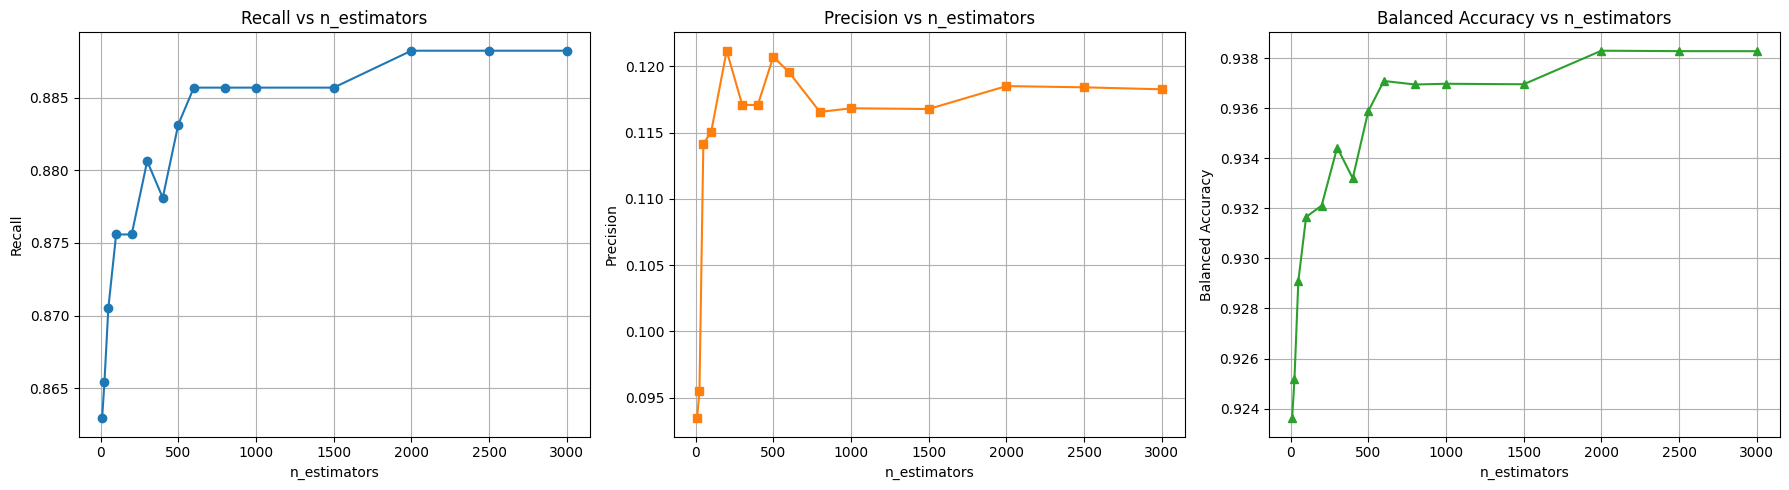

In [ ]:
# Диапазон количества деревьев
n_estimators_range = [10, 25, 50, 100, 200, 300, 400, 500, 600, 800, 1000, 1500, 2000, 2500, 3000]
recalls = []
precisions = []
balanced_accuracies = []

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

for n in n_estimators_range:
    clf = BalancedRandomForestClassifier(n_estimators=n, random_state=random_state, n_jobs=-1)
    fold_recalls = []
    fold_precisions = []
    fold_balacc = []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)

        fold_recalls.append(recall_score(y_val, y_pred))
        fold_precisions.append(precision_score(y_val, y_pred))
        fold_balacc.append(balanced_accuracy_score(y_val, y_pred))

    recalls.append(np.mean(fold_recalls))
    precisions.append(np.mean(fold_precisions))
    balanced_accuracies.append(np.mean(fold_balacc))

# График
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

# Recall
axes[0].plot(n_estimators_range, recalls, marker='o', color='tab:blue')
axes[0].set_title('Recall vs n_estimators')
axes[0].set_xlabel('n_estimators')
axes[0].set_ylabel('Recall')
axes[0].grid(True)

# Precision
axes[1].plot(n_estimators_range, precisions, marker='s', color='tab:orange')
axes[1].set_title('Precision vs n_estimators')
axes[1].set_xlabel('n_estimators')
axes[1].set_ylabel('Precision')
axes[1].grid(True)

# Balanced Accuracy
axes[2].plot(n_estimators_range, balanced_accuracies, marker='^', color='tab:green')
axes[2].set_title('Balanced Accuracy vs n_estimators')
axes[2].set_xlabel('n_estimators')
axes[2].set_ylabel('Balanced Accuracy')
axes[2].grid(True)

plt.tight_layout()
plt.show()

В ходе эксперимента с различными значениями n_estimators наблюдается устойчивое улучшение метрик Recall и Balanced Accuracy по мере увеличения числа деревьев. Максимальные значения этих метрик достигаются при n_estimators = 2000.

Поиск оптимальных гиперпараметров (GridSearch)

In [ ]:
from sklearn.model_selection import GridSearchCV
# Гиперпараметры для подбора
param_grid = {
    'max_depth': [10, 11, 12]
}

# Стратифицированная кросс-валидация
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

# Кастомный ско́рер по balanced accuracy
scorer = make_scorer(balanced_accuracy_score)

# BalancedRandomForestClassifier
brf = BalancedRandomForestClassifier(random_state=random_state, n_jobs=-1, n_estimators=2000, replacement=False, max_features='log2', min_samples_leaf=1, min_samples_split=2)

# GridSearch
grid_search = GridSearchCV(
    estimator=brf,
    param_grid=param_grid,
    scoring=scorer,
    cv=cv,
    verbose=2,
    n_jobs=-1
)

# Обучение
grid_search.fit(X, y)

# Лучшие параметры и метрика
print("Лучшие параметры:")
print(grid_search.best_params_)
print(f"Balanced Accuracy (CV): {grid_search.best_score_:.4f}")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Лучшие параметры:
{'max_depth': 11}
Balanced Accuracy (CV): 0.9452


Среди рассмотренных комбинаций наилучший результат по метрике Balanced Accuracy показала следующая конфигурация:
- n_estimators=2000
- replacement=False
- max_features='log2'
- min_samples_leaf=1
- min_samples_split=2
- max_depth=11

##### Оптимизация порога классификации

Лучший порог по CV Balanced Accuracy: 0.4554


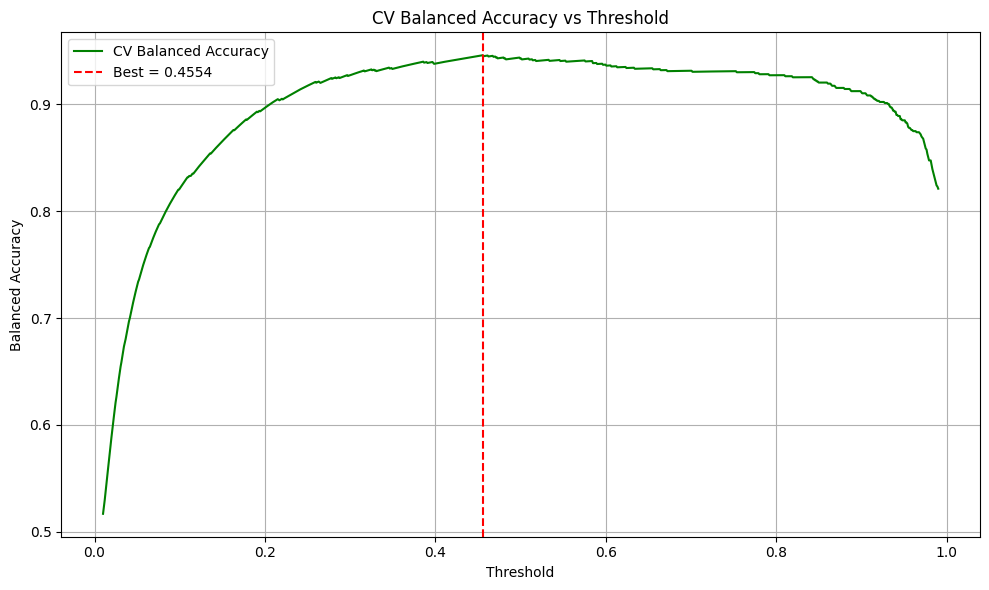

In [ ]:
# Настройка
thresholds = np.linspace(0.01, 0.99, 1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
balanced_accuracies_per_threshold = np.zeros(len(thresholds))

# Цикл по фолдам
for train_idx, valid_idx in cv.split(X, y):
    X_train_cv, X_valid_cv = X.iloc[train_idx], X.iloc[valid_idx]
    y_train_cv, y_valid_cv = y.iloc[train_idx], y.iloc[valid_idx]

    clf = BalancedRandomForestClassifier(random_state=random_state, n_jobs=-1, n_estimators=2000, replacement=False, max_features='log2', min_samples_leaf=1, min_samples_split=2, max_depth=11)
    clf.fit(X_train_cv, y_train_cv)

    y_valid_scores = clf.predict_proba(X_valid_cv)[:, 1]

    # Вычисляем Balanced Accuracy для всех порогов
    for i, t in enumerate(thresholds):
        y_pred_t = (y_valid_scores >= t).astype(int)
        balanced_accuracies_per_threshold[i] += balanced_accuracy_score(y_valid_cv, y_pred_t)

# Среднее значение по фолдам
balanced_accuracies_per_threshold /= cv.get_n_splits()

# Выбор лучшего порога
best_idx = np.argmax(balanced_accuracies_per_threshold)
best_threshold = thresholds[best_idx]
print(f"Лучший порог по CV Balanced Accuracy: {best_threshold:.4f}")

# График
plt.figure(figsize=(10, 6))
plt.plot(thresholds, balanced_accuracies_per_threshold, label='CV Balanced Accuracy', color='green')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best = {best_threshold:.4f}')
plt.xlabel("Threshold")
plt.ylabel("Balanced Accuracy")
plt.title("CV Balanced Accuracy vs Threshold")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Поскольку модель BalancedRandomForest по умолчанию классифицирует по порогу 0.5, было проведено дополнительное исследование зависимости метрик от порога. Наилучший результат по метрике Balanced Accuracy достигнут при пороге 0.4554, что позволило улучшить баланс между распознаванием положительного класса и точностью предсказаний.

#### Оптимизация ансамбля XGBoost

Для начала определимся с методом ресемплинга

In [ ]:
scoring = {
    'accuracy': accuracy_score,
    'precision': precision_score,
    'recall': recall_score,
    'f1': f1_score,
    'PR-AUC': average_precision_score,
    'roc_auc': roc_auc_score,
    'balanced_accuracy': balanced_accuracy_score,
    'mcc': matthews_corrcoef,
    'kappa': cohen_kappa_score,
    'gmean': g_mean_score
}

resamplers = {
    "NoResample": DummyResampler(),
    "SMOTE": SMOTE(),
    "ADASYN": ADASYN(),
    "GAN": GAN(epochs=200)
}

xgb = XGBClassifier(eval_metric='logloss')

results = {}
for name, sampler in resamplers.items():
    print(f"Running: XGB + {name}")
    results[f"XGB_{name}"] = cross_validate_with_resampling(X_train, y_train, xgb, sampler, cv=5)

# Финальный датафрейм
results_df5 = pd.DataFrame(results)

Running: XGB + NoResample
Running: XGB + SMOTE
Running: XGB + ADASYN
Running: XGB + GAN
5677/5677 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
5677/5677 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
5677/5677 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step
5677/5677 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
5677/5677 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step


In [ ]:
results_df5

,XGB_NoResample,XGB_SMOTE,XGB_ADASYN,XGB_GAN
ACCURACY,0.999561,0.999333,0.999241,0.999557
PRECISION,0.952786,0.803328,0.757354,0.942679
RECALL,0.786758,0.822265,0.829925,0.791821
F1,0.860712,0.809971,0.790452,0.859559
PR-AUC,0.843310,0.835639,0.829084,0.844067
ROC_AUC,0.979540,0.974925,0.975483,0.979166
BALANCED_ACCURACY,0.893344,0.910952,0.914730,0.895869
MCC,0.865020,0.811052,0.791669,0.863184
KAPPA,0.860495,0.809638,0.790073,0.859339
GMEAN,0.886692,0.906031,0.910391,0.889167


- Использование SMOTE и ADASYN привело к незначительному увеличению Recall, однако при этом произошло значительное снижение Precision

- Использование GAN привело к более сбалансированным метрикам, однако он не обеспечил значительного прироста по сравнению с базовой моделью.

- Наилучшие возможности для повышения Recall за счет понижения Precision имеет XGBoost без ресемплинга.

##### Оптимизация веса положительного класса (scale_pos_weight)

С помощью перебора значений параметра scale_pos_weight найдём оптимальную настройку, позволяющую максимизировать метрику Balanced Accuracy.

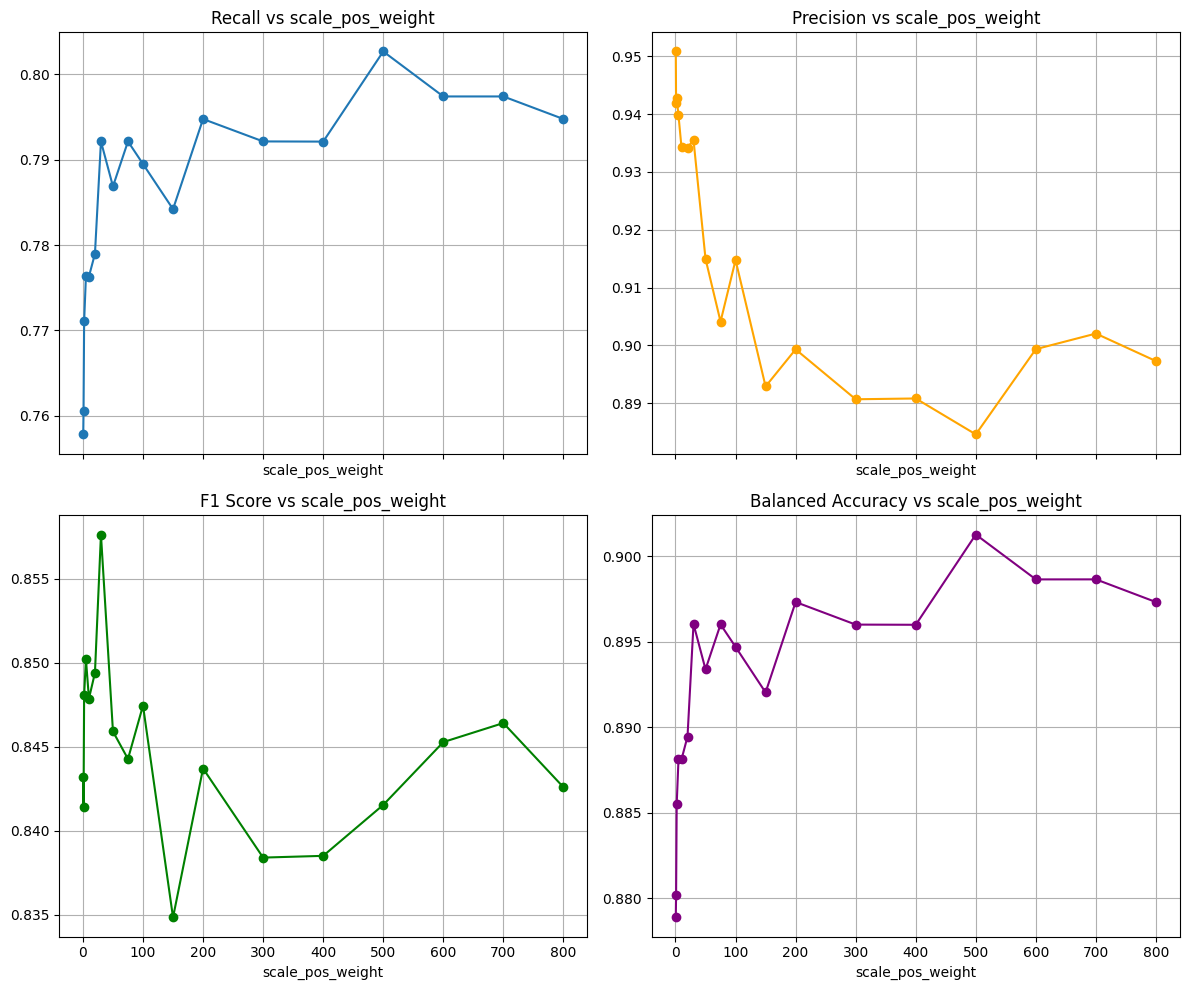

In [ ]:
# Диапазон значений весов
weights = [0.5, 1, 2, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500, 600, 700, 800]

# Метрики
recalls = []
precisions = []
f1s = []
balanced_accuracies = []

# Кросс-валидация
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

for w in weights:
    clf = XGBClassifier(scale_pos_weight=w, eval_metric='logloss')
    fold_recall, fold_precision, fold_f1, fold_balacc = [], [], [], []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_val)

        fold_recall.append(recall_score(y_val, y_pred))
        fold_precision.append(precision_score(y_val, y_pred, zero_division=0))
        fold_f1.append(f1_score(y_val, y_pred))
        fold_balacc.append(balanced_accuracy_score(y_val, y_pred))

    recalls.append(np.mean(fold_recall))
    precisions.append(np.mean(fold_precision))
    f1s.append(np.mean(fold_f1))
    balanced_accuracies.append(np.mean(fold_balacc))

# Визуализация
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True)

axes[0, 0].plot(weights, recalls, marker='o', label='Recall')
axes[0, 0].set_title('Recall vs scale_pos_weight')
axes[0, 0].grid(True)

axes[0, 1].plot(weights, precisions, marker='o', label='Precision', color='orange')
axes[0, 1].set_title('Precision vs scale_pos_weight')
axes[0, 1].grid(True)

axes[1, 0].plot(weights, f1s, marker='o', label='F1', color='green')
axes[1, 0].set_title('F1 Score vs scale_pos_weight')
axes[1, 0].grid(True)

axes[1, 1].plot(weights, balanced_accuracies, marker='o', label='Balanced Accuracy', color='purple')
axes[1, 1].set_title('Balanced Accuracy vs scale_pos_weight')
axes[1, 1].grid(True)

for ax in axes.flat:
    ax.set_xlabel('scale_pos_weight')

plt.tight_layout()
plt.show()


Лучший результат достигнут при scale_pos_weight = 500

##### Регуляризация

Для снижения переобучения и повышения обобщающей способности модели проведём поиск оптимальных значений регуляризационных параметров.

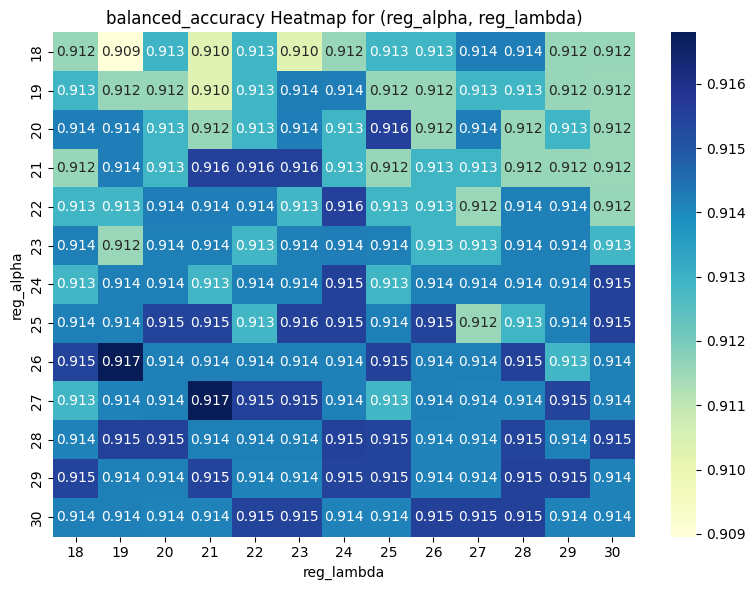

In [ ]:
# Сетка значений регуляризации
alphas = [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
lambdas = [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
# Хранение результатов
results = []

# Кросс-валидация
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

for alpha in alphas:
    for lamb in lambdas:
        clf = XGBClassifier(
            eval_metric='logloss',
            reg_alpha=alpha,
            reg_lambda=lamb,
            scale_pos_weight=500
        )

        recall_scores, precision_scores, f1_scores, balacc_scores = [], [], [], []

        for train_idx, val_idx in skf.split(X_train, y_train):
            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

            clf.fit(X_tr, y_tr)
            y_pred = clf.predict(X_val)

            recall_scores.append(recall_score(y_val, y_pred))
            precision_scores.append(precision_score(y_val, y_pred, zero_division=0))
            f1_scores.append(f1_score(y_val, y_pred))
            balacc_scores.append(balanced_accuracy_score(y_val, y_pred))

        results.append({
            'alpha': alpha,
            'lambda': lamb,
            'recall': np.mean(recall_scores),
            'precision': np.mean(precision_scores),
            'f1': np.mean(f1_scores),
            'balanced_accuracy': np.mean(balacc_scores)
        })

# В DataFrame
results_df = pd.DataFrame(results)

# Тепловая карта F1 (можно заменить на любую метрику)
pivot_f1 = results_df.pivot(index='alpha', columns='lambda', values='balanced_accuracy')

plt.figure(figsize=(8, 6))
plt.title("balanced_accuracy Heatmap for (reg_alpha, reg_lambda)")
sns.heatmap(pivot_f1, annot=True, fmt=".3f", cmap="YlGnBu")
plt.xlabel("reg_lambda")
plt.ylabel("reg_alpha")
plt.tight_layout()
plt.show()


Максимальное значение Balanced Accuracy достигнуто при следующих настройках:
- lambda=21
- alpha=27

##### Поиск наилучшего порога классификации

Лучший порог по CV Balanced Accuracy: 0.0100


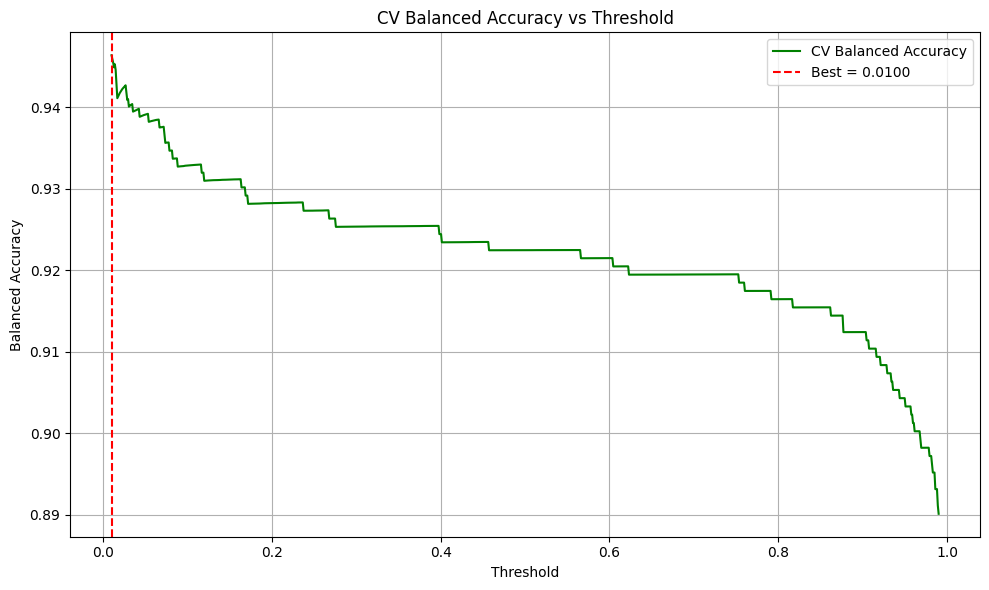

In [ ]:
# Настройка
thresholds = np.linspace(0.01, 0.99, 1000)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
balanced_accuracies_per_threshold = np.zeros(len(thresholds))

# Цикл по фолдам
for train_idx, valid_idx in cv.split(X, y):
    X_train_cv, X_valid_cv = X.iloc[train_idx], X.iloc[valid_idx]
    y_train_cv, y_valid_cv = y.iloc[train_idx], y.iloc[valid_idx]

    clf = XGBClassifier(
        eval_metric='logloss',
        reg_alpha=27,
        reg_lambda=21,
        scale_pos_weight=500
    )
    clf.fit(X_train_cv, y_train_cv)

    y_valid_scores = clf.predict_proba(X_valid_cv)[:, 1]

    # Вычисляем Balanced Accuracy для всех порогов
    for i, t in enumerate(thresholds):
        y_pred_t = (y_valid_scores >= t).astype(int)
        balanced_accuracies_per_threshold[i] += balanced_accuracy_score(y_valid_cv, y_pred_t)

# Среднее значение по фолдам
balanced_accuracies_per_threshold /= cv.get_n_splits()

# Выбор лучшего порога
best_idx = np.argmax(balanced_accuracies_per_threshold)
best_threshold = thresholds[best_idx]
print(f"Лучший порог по CV Balanced Accuracy: {best_threshold:.4f}")

# График
plt.figure(figsize=(10, 6))
plt.plot(thresholds, balanced_accuracies_per_threshold, label='CV Balanced Accuracy', color='green')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best = {best_threshold:.4f}')
plt.xlabel("Threshold")
plt.ylabel("Balanced Accuracy")
plt.title("CV Balanced Accuracy vs Threshold")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Наилучший порог: 0.01

#### Финальное сравнение моделей

В результате проведённой оптимизации были отобраны две лучшие модели c данными параметрами:

- XGBClassifier(eval_metric='logloss', reg_alpha=27, reg_lambda=21, scale_pos_weight=500) с порогом 0.01

- BalancedRandomForestClassifier(n_estimators=2000, replacement=False, max_features='log2', min_samples_leaf=1, min_samples_split=2, max_depth=11) с порогом  0.4554

Для объективного сравнения моделей проведем Stratified 10-fold кросс-валидацию, с расчётом среднего количества выявленных мошеннических транзакций, числа ложных срабатываний и времени обучения.

In [ ]:
# Параметры моделей и пороги
xgb_params = {
    'eval_metric': 'logloss',
    'reg_alpha': 27,
    'reg_lambda': 21,
    'scale_pos_weight': 500
}
xgb_threshold = 0.01

brf_params = {
    'n_jobs': -1,
    'n_estimators': 2000,
    'replacement': False,
    'max_features': 'log2',
    'min_samples_leaf': 1,
    'min_samples_split': 2,
    'max_depth': 11
}
brf_threshold = 0.4554

# Stratified CV
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=random_state)

# Результаты
results = {
    'Model': [],
    'Accuracy': [],
    'Balanced Accuracy': [],
    'Recall': [],
    'Precision': [],
    'F1 Score': [],
    'Frauds Detected': [],
    'False Positives': [],
    'FP/Fraud Ratio': [],
    'Train Time (s)': []
}

def evaluate_model(clf, threshold, X, y, model_name):
    for train_idx, test_idx in cv.split(X, y):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        start_time = time.time()
        clf.fit(X_train, y_train)
        train_time = time.time() - start_time

        y_scores = clf.predict_proba(X_test)[:, 1]
        y_preds = (y_scores >= threshold).astype(int)

        acc = accuracy_score(y_test, y_preds)
        bacc = balanced_accuracy_score(y_test, y_preds)
        recall = recall_score(y_test, y_preds)
        precision = precision_score(y_test, y_preds)
        f1 = f1_score(y_test, y_preds)

        cm = confusion_matrix(y_test, y_preds)
        tn, fp, fn, tp = cm.ravel()

        results['Model'].append(model_name)
        results['Accuracy'].append(acc)
        results['Balanced Accuracy'].append(bacc)
        results['Recall'].append(recall)
        results['Precision'].append(precision)
        results['F1 Score'].append(f1)
        results['Frauds Detected'].append(tp)
        results['False Positives'].append(fp)
        results['FP/Fraud Ratio'].append(fp / tp if tp > 0 else np.nan)
        results['Train Time (s)'].append(train_time)

# Оценим обе модели
evaluate_model(XGBClassifier(**xgb_params), xgb_threshold, X, y, "XGBoost")
evaluate_model(BalancedRandomForestClassifier(**brf_params), brf_threshold, X, y, "BalancedRF")

# Сводная таблица со средними значениями по фолдам
df_results = pd.DataFrame(results)
summary = df_results.groupby('Model').mean().round(4)

In [ ]:
summary

,Accuracy,Balanced Accuracy,Recall,Precision,F1 Score,Frauds Detected,False Positives,FP/Fraud Ratio,Train Time (s)
Model,,,,,,,,,
BalancedRF,0.9701,0.9454,0.9207,0.0508,0.0963,45.3,847.5,18.7191,89.9088
XGBoost,0.9852,0.9449,0.9044,0.0967,0.1746,44.5,416.9,9.3702,5.2992


Balanced Random Forest Classifier ловит 92% всех мошеннеческий транзакций. Каждая пойманная транзакция стоит 19 ложно пойманных транзакций.

XGBoost Classifier ловит 90% всех мошеннеческих транзакций, ценой только 9 ошибок.

В среднем Balanced Random Forest Classifier ошибается в 2 раза чаще и обучается в 17 раз дольше

Вывод:

Хотя Balanced Random Forest демонстрирует несколько более высокий показатель Recall, его высокая вычислительная стоимость и вдвое большее число ложных срабатываний делают его менее практичным выбором.

С учётом высокой чувствительности, низкой стоимости ошибки, а также высокой скорости обучения, наилучшей моделью по совокупности метрик и прикладной применимости признаётся XGBClassifier(eval_metric='logloss', reg_alpha=27, reg_lambda=21, scale_pos_weight=500) с индивидуально подобранным порогом 0.01.

## 9. Итоговая конфигурация и pipeline

Наилучшей моделью для классификации Мошеннеческих Транзакций является:

XGBClassifier(eval_metric='logloss', reg_alpha=27, reg_lambda=21, scale_pos_weight=500) с индивидуально подобранным порогом 0.01

Оценим эффективность модели с использованием графиков обучения, построенных на основе 10-кратной стратифицированной кросс-валидации.
На каждом из 10 фолдов модель обучается на случайной подвыборке данных, сохраняющей исходное соотношение классов, и тестируется на соответствующей отложенной части. Это позволяет объективно оценить обобщающую способность модели и устойчивость метрик к различным срезам данных.

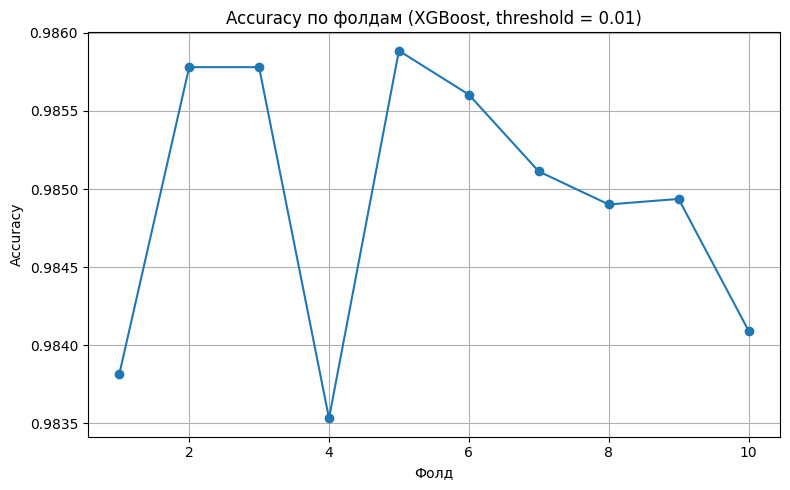

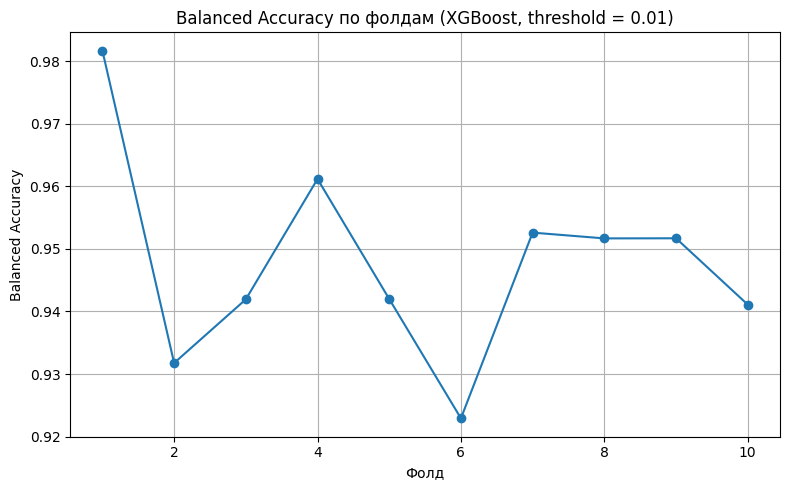

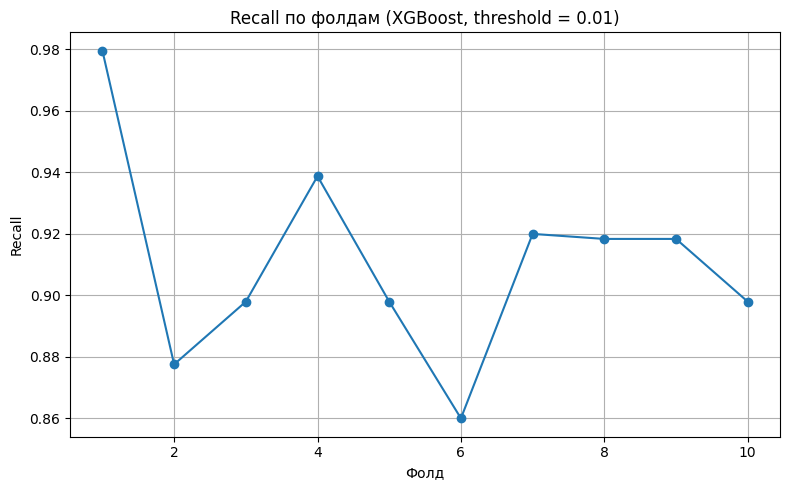

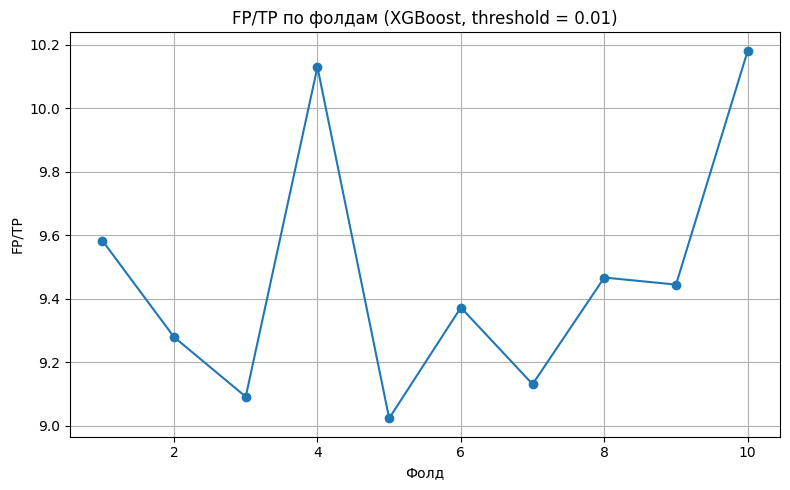

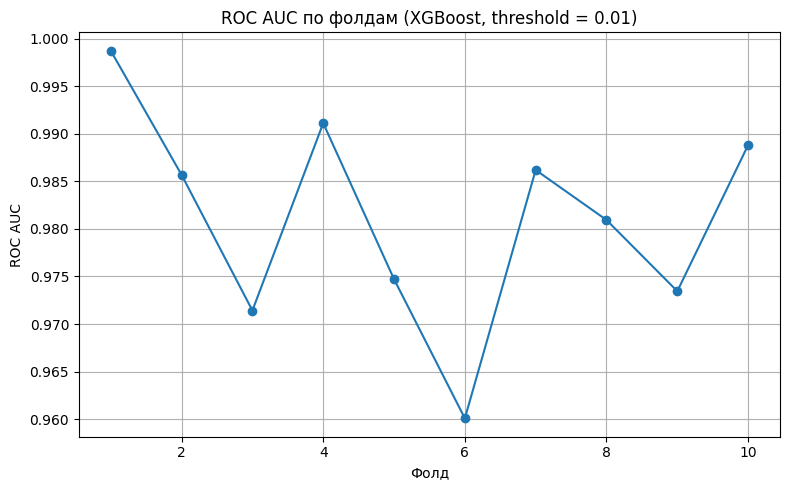

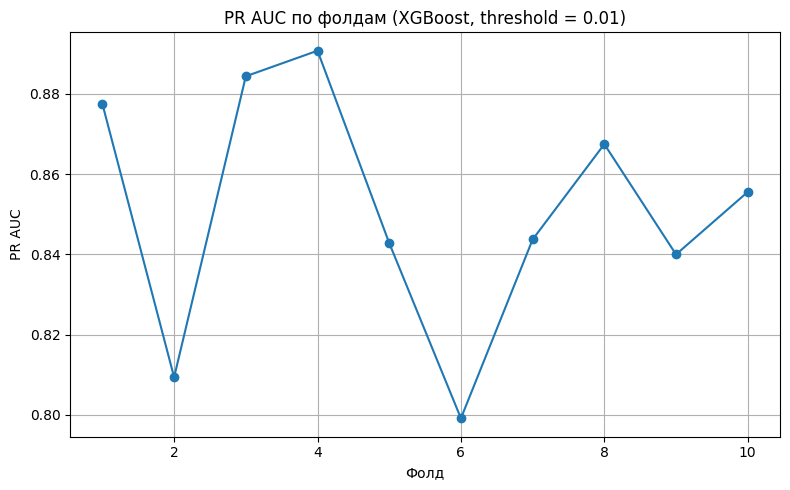

In [ ]:
xgb_params = {
    'eval_metric': 'logloss',
    'reg_alpha': 27,
    'reg_lambda': 21,
    'scale_pos_weight': 500
}
threshold = 0.01

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=random_state)
metrics = {
    'Accuracy': [],
    'Balanced Accuracy': [],
    'Recall': [],
    'FP/TP': [],
    'ROC AUC': [],
    'PR AUC': []
}

# Кросс-валидация
for train_idx, test_idx in cv.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    clf = XGBClassifier(**xgb_params)
    clf.fit(X_train, y_train)

    y_scores = clf.predict_proba(X_test)[:, 1]
    y_preds = (y_scores >= threshold).astype(int)

    # Матрица ошибок для вычисления TP и FP
    tn, fp, fn, tp = confusion_matrix(y_test, y_preds).ravel()
    fp_tp_ratio = fp / tp if tp > 0 else np.nan

    metrics['Accuracy'].append(accuracy_score(y_test, y_preds))
    metrics['Balanced Accuracy'].append(balanced_accuracy_score(y_test, y_preds))
    metrics['Recall'].append(recall_score(y_test, y_preds))
    metrics['FP/TP'].append(fp_tp_ratio)
    metrics['ROC AUC'].append(roc_auc_score(y_test, y_scores))
    metrics['PR AUC'].append(average_precision_score(y_test, y_scores))

for metric_name, values in metrics.items():
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(values) + 1), values, marker='o', linestyle='-')
    plt.title(f'{metric_name} по фолдам (XGBoost, threshold = 0.01)')
    plt.xlabel('Фолд')
    plt.ylabel(metric_name)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Результаты 10-кратной стратифицированной кросс-валидации демонстрируют стабильную эффективность модели по ключевым метрикам:

- Accuracy: 0.984 – 0.986 — высокая общая точность классификации.

- Balanced Accuracy: 0.925 – 0.985 — отражает сбалансированное качество по обоим классам.

- Recall (полнота): 0.86 – 0.98 — указывает на высокую чувствительность модели к выявлению мошеннических транзакций, что критично в данной задаче.

- FP/TP (ложные тревоги на одно настоящее мошенничество): модель в среднем выдаёт 9–10 ложных срабатываний на каждое реально обнаруженное мошенничество. Это соотношение уместно при приоритете на максимум выявленных нарушений и готовности к нагрузке на проверку.

- ROC AUC: 0.96 – 0.998 — модель хорошо различает классы по вероятностному выходу.

- PR AUC: 0.80 – 0.89 — высокая площадь под кривой Precision-Recall, особенно важной в условиях дисбаланса.

Результаты кросс-валидации подтверждают, что выбранная конфигурация XGBoost с порогом 0.01 эффективно решает задачу обнаружения мошенничества при приемлемом уровне ложных тревог.

Итоговый pipeline и его применение (на примере случайной мошеннической транзакции):

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# 1. Загрузка датасета
df = pd.read_csv('creditcard.csv')

# 2. Разделение на признаки и целевой столбец
X = df.drop(columns='Class')
y = df['Class']

## Выбор случайной мошеннической транзакции (для примера применения pipeline)
fraud_idx = y[y == 1].sample(random_state=25).index[0]
fraud_sample = X.loc[[fraud_idx]]
fraud_true_label = y.loc[fraud_idx]
# Исключение этой строки из обучающего датасета
X_train = X.drop(index=fraud_idx)
y_train = y.drop(index=fraud_idx)

# ---------------- Pipeline ---------------- #
columns_to_scale = ['Time', 'Amount']

preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', RobustScaler(), columns_to_scale)
    ],
    remainder='passthrough'
)

pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('xgb', XGBClassifier(
        eval_metric='logloss',
        reg_alpha=27,
        reg_lambda=21,
        scale_pos_weight=500,
        random_state=25
    ))
])

# 5. Обучение pipeline
pipeline.fit(X_train, y_train)

# 6. Предсказание
probability = 0.01
fraud_proba = pipeline.predict_proba(fraud_sample)[:, 1][0]
fraud_pred = int(fraud_proba >= probability)
print(f"Вероятность мошенничества: {fraud_proba:.6f}")
print(f"Предсказание: {'Мошенничество (1)' if fraud_pred == 1 else 'Обычная транзакция (0)'}")

Вероятность мошенничества: 0.999539
Предсказание: Мошенничество (1)


## 10. Заключение и перспективы решения проблемы:

### Основные выводы исследования:

В ходе выполнения курсовой работы была решена задача повышения эффективности классификации в условиях ярко выраженного дисбаланса классов на примере датасета кредитных транзакций, где доля мошеннических операций составляла менее 0.2 %. Были рассмотрены и протестированы различные подходы к борьбе с дисбалансом на всех трёх уровнях:

- На уровне данных: классические методы Undersampling (RandomUndersampling, NearMiss, Cluster Centroids), Oversampling (RandomOversampling, SMOTE, ADASYN, GAN);

- На уровне алгоритмов: использование параметров class_weight, смещение порога классификации;

- Ансамблевые и гибридные подходы: BalancedBaggingClassifier, BalancedRandomForest, EasyEnsembleClassifier, XGBClassifier + SMOTE/ADASYN/GAN, XGBClassifier/AdaBoostClassifier с взвешиванием классов, LGBMClassifier с is_unbalance=True, RUSBoost.

Результаты показали, что:

- Требуется аккуратный выбор метрик, так как обычный Accuracy не раскрывает полную картину. Важно рассматривать метрики, такие как Balanced Accuracy, а также учитывать стоимость ошибочной классификации при оптимизации как Recall, так и Precision.

- Наилучшие показатели Recall достигнуты при использовании методов ресемплирования, методов взвешевания классов, калибровкой порога классификации.

- Классические модели без балансировки (Logistic Regression, Random Forest) демонстрировали высокую точность, но пониженный recall.

- Критически важным оказалась настройка порога классификации, он значительно повышал Recall.

- Таким образом, оптимальной стратегией в данной задаче является использование ансамблевых методов и последующей оптимизацией порога классификации.

### Перспективы и направления дальнейших исследований
- Адаптивный выбор метода балансировки под конкретный датасет. На практике не существует одного универсального метода, который работает одинаково хорошо на всех наборах данных. Поэтому перспективной идеей является разработка мета-алгоритма, который анализирует свойства датасета (количество признаков, уровень дисбаланса, распределения), автоматически выбирает наиболее подходящий метод (например, SMOTE, ADASYN, BorderlineSMOTE, GAN или комбинированный),настраивает параметры (k в SMOTE, стратегия sampling).

- Комбинирование слабых детекторов в self-ensembling. Интересное направление — использовать множество "слабых" моделей (например, деревья, KNN или небольшие нейросети), которые обучаются на случайно сбалансированных подвыборках. После этого объединяются их вероятности или ранги. Такой подход снижает переобучение,устойчив к шуму и эффективен при высокой редкости положительного класса.

- Учет стоимости ошибок в реальном времени (cost-aware learning). Вместо того чтобы просто повышать recall, можно напрямую обучать модель с учётом бизнес-стоимости ошибок. Например, пропущенная мошенническая транзакция = 1000 euro убытка, а Ложная тревога = 10 euro затрат на ручную проверку. Использование асимметричных функций позволит напрямую минимизировать потенциальный ущерб, а не только улучшать метрики.

### Вывод:
Проблема дисбаланса классов остаётся фундаментальной и практически значимой задачей в машинном обучении. Результаты данной работы подтверждают эффективность комплексного подхода, сочетающего подготовку данных, грамотный выбор модели и постобработку результата. Предложенные методы и выводы могут быть использованы в реальных системах обнаружения мошенничества и других критически важных задачах, где ошибка в отношении миноритарного класса может иметь серьёзные последствия.